<a href="https://colab.research.google.com/github/EmanuelMatiasCinel/Proyecto-Final-Data-Science/blob/main/Grupo_16_Proyecto_Final_Completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grupo 16 - Proyecto Data Science
## Predicción de la dirección anual del precio de acciones a partir de indicadores financiero-contables

**Contenido:** Parte I, análisis exploratorio (secciones 0 a 9). Parte II, modelo supervisado (sección 10). Se ejecuta de arriba hacia abajo: la Parte I genera `financial_data_unificado.csv`, que la Parte II vuelve a leer.

 **Objetivo**: construir un modelo de clasificación que, a partir de los indicadores financiero-contables de una empresa en el año t, prediga si su acción sube o baja durante el año t+1. Como análisis complementario, se agrupan las empresas por perfil financiero (clustering) para ver si ciertos perfiles se asocian a mayor probabilidad de suba. El modelo no pretende predecir precios con precisión, sino evaluar si los fundamentals contienen alguna señal y construir una base reutilizable para futuras ampliaciones.

**Fuente de datos**: “200+ Financial Indicators of US stocks (2014-2018)”, Kaggle, usuario Nicolas Carbone (https://www.kaggle.com/datasets/cnic92/200-financial-indicators-of-us-stocks-20142018). Cada archivo anual contiene más de 200 indicadores por empresa, el sector y la variación de precio del año siguiente.

**Variable objetivo**: `Class` (en la notebook, `clase`): 1 = la acción sube en el año siguiente, 0 = no sube. Coincide con que la variación de precio del año siguiente sea positiva.

# PARTE I: Exploración de Datos

## 0. Preparación del entorno

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 1. Carga y unificación de los 5 años

Se cargan los 5 archivos (`2014_Financial_Data.csv` a `2018_Financial_Data.csv`). Primero se mira la estructura de uno solo (2014): cuántas filas y columnas tiene y de qué tipo es cada variable.

In [5]:
#define los data frames y lee los .csv

df= pd.read_csv("2014_Financial_Data.csv")
df1= pd.read_csv("2015_Financial_Data.csv")
df2= pd.read_csv("2016_Financial_Data.csv")
df3= pd.read_csv("2017_Financial_Data.csv")
df4= pd.read_csv("2018_Financial_Data.csv")

#imprime por consola las primeras 5 filas del DataFrame
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
display(df.head())
display(df.tail())

# Imprime info completa del DF
print(df.info())

# Obtengo el nombre de las columnas
df.columns

Filas: 3808 | Columnas: 225


,Unnamed: 0,Revenue,Revenue Growth,Cost of Revenue,Gross Profit,R&D Expenses,SG&A Expense,Operating Expenses,Operating Income,Interest Expense,Earnings before Tax,Income Tax Expense,Net Income - Non-Controlling int,Net Income - Discontinued ops,Net Income,Preferred Dividends,Net Income Com,EPS,EPS Diluted,Weighted Average Shs Out,Weighted Average Shs Out (Dil),Dividend per Share,Gross Margin,EBITDA Margin,EBIT Margin,...,10Y Revenue Growth (per Share),5Y Revenue Growth (per Share),3Y Revenue Growth (per Share),10Y Operating CF Growth (per Share),5Y Operating CF Growth (per Share),3Y Operating CF Growth (per Share),10Y Net Income Growth (per Share),5Y Net Income Growth (per Share),3Y Net Income Growth (per Share),10Y Shareholders Equity Growth (per Share),5Y Shareholders Equity Growth (per Share),3Y Shareholders Equity Growth (per Share),10Y Dividend per Share Growth (per Share),5Y Dividend per Share Growth (per Share),3Y Dividend per Share Growth (per Share),Receivables growth,Inventory Growth,Asset Growth,Book Value per Share Growth,Debt Growth,R&D Expense Growth,SG&A Expenses Growth,Sector,2015 PRICE VAR [%],Class
0,PG,7.440100e+10,-0.0713,3.903000e+10,3.537100e+10,0.000000e+00,2.146100e+10,2.146100e+10,1.391000e+10,7.090000e+08,1.449400e+10,2.851000e+09,1.420000e+08,-1.127000e+09,1.164300e+10,0.0,1.164300e+10,4.1900,4.010,2.705960e+09,2.705960e+09,2.448,0.4754,0.2470,0.2043,...,0.0323,0.0088,-0.0182,0.0355,0.0015,0.0260,0.0603,-0.0137,0.0060,0.1442,0.0353,0.0201,0.1013,0.0834,0.0751,-0.0187,-0.0217,0.0359,0.0316,0.1228,0.0000,-0.1746,Consumer Defensive,-9.323276,0
1,VIPS,3.734148e+09,1.1737,2.805625e+09,9.285226e+08,1.083303e+08,3.441414e+08,7.939267e+08,1.345959e+08,1.214869e+07,1.753823e+08,3.955957e+07,-1.431918e+07,0.000000e+00,1.358227e+08,0.0,1.358227e+08,0.2396,0.226,NaN,1.829362e+07,0.000,0.2487,0.0107,0.0502,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.6484,1.7313,Consumer Defensive,-25.512193,0
2,KR,9.837500e+10,0.0182,7.813800e+10,2.023700e+10,0.000000e+00,1.519600e+10,1.751200e+10,2.725000e+09,4.430000e+08,2.270000e+09,7.510000e+08,1.200000e+07,0.000000e+00,1.519000e+09,0.0,1.519000e+09,1.4700,1.450,1.033053e+09,1.028000e+09,0.307,0.2057,0.0450,0.0276,...,0.1027,0.1038,0.1399,0.0889,0.0937,0.0946,0.2272,0.0906,0.1892,0.0676,0.0558,0.0789,0.0000,0.1215,0.1633,0.0618,0.0981,0.1886,0.3268,0.2738,0.0000,0.0234,Consumer Defensive,33.118297,1
3,RAD,2.552641e+10,0.0053,1.820268e+10,7.323734e+09,0.000000e+00,6.561162e+09,6.586482e+09,7.372520e+08,4.245910e+08,2.502180e+08,8.040000e+05,0.000000e+00,0.000000e+00,2.494140e+08,33998000.0,2.154160e+08,4.6000,4.600,4.832628e+07,4.832628e+07,0.000,0.2869,0.0420,0.0264,...,-0.0195,-0.0290,-0.0230,0.0513,0.1164,0.1777,0.0480,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0211,-0.0510,-0.0189,0.1963,-0.0458,0.0000,-0.0060,Consumer Defensive,2.752291,1
4,GIS,1.790960e+10,0.0076,1.153980e+10,6.369800e+09,0.000000e+00,3.474300e+09,3.412400e+09,2.957400e+09,3.024000e+08,2.707700e+09,8.833000e+08,3.690000e+07,0.000000e+00,1.824400e+09,0.0,1.824400e+09,2.9000,2.830,6.144922e+08,6.144922e+08,1.550,0.3557,0.2010,0.1681,...,0.0704,0.0567,0.0773,0.0782,0.0828,0.1991,0.0776,0.0841,0.0177,0.0427,0.0623,0.0217,0.1092,0.1250,0.1144,0.0257,0.0090,0.0215,0.0274,0.1025,0.0000,-0.0220,Consumer Defensive,12.897715,1


,Unnamed: 0,Revenue,Revenue Growth,Cost of Revenue,Gross Profit,R&D Expenses,SG&A Expense,Operating Expenses,Operating Income,Interest Expense,Earnings before Tax,Income Tax Expense,Net Income - Non-Controlling int,Net Income - Discontinued ops,Net Income,Preferred Dividends,Net Income Com,EPS,EPS Diluted,Weighted Average Shs Out,Weighted Average Shs Out (Dil),Dividend per Share,Gross Margin,EBITDA Margin,EBIT Margin,...,10Y Revenue Growth (per Share),5Y Revenue Growth (per Share),3Y Revenue Growth (per Share),10Y Operating CF Growth (per Share),5Y Operating CF Growth (per Share),3Y Operating CF Growth (per Share),10Y Net Income Growth (per Share),5Y Net Income Growth (per Share),3Y Net Income Growth (per Share),10Y Shareholders Equity Growth (per Share),5Y Shareholders Equity Growth (per Share),3Y Shareholders Equity Growth (per Share),10Y Dividend per Share Growth (per Share),5Y Dividend per Share Growth (per Share),3Y Dividend per Share Growth (per Share),Receivables growth,Inventory Growth,Asset Growth,Book Value per Share Growth,Debt Growth,R&D Expense Growth,SG&A Expenses Growth,Sector,2015 PRICE VAR [%],Class
3803,TSRI,49529867.0,0.1028,41251638.0,8278229.0,0.0,8253061.0,8253061.0,25168.0,0.0,-68936.0,17000.0,102824.0,0.0,-85936.0,0.0,-85936.0,-0.04,-0.04,1962062.0,1962062.0,0.00,0.167100,-0.001000,-0.00140,...,0.0104,0.0455,0.0902,-0.0605,-0.1906,0.0000,0.0000,0.0000,0.0000,-0.0387,-0.0511,-0.1055,-1.0000,-1.0000,0.0000,-0.0384,0.0000,-0.0041,-0.0049,0.0000,0.0000,0.0213,Technology,29.362884,1
3804,TZOO,153240000.0,-0.1019,19174000.0,134066000.0,11326000.0,112513000.0,116256000.0,17810000.0,0.0,17901000.0,4839000.0,0.0,0.0,13062000.0,0.0,13062000.0,0.88,0.88,14730454.0,14768000.0,0.00,0.874900,0.136000,0.11680,...,0.1792,0.1262,0.0450,0.0000,0.0000,0.0000,0.0948,0.2286,0.6322,0.0017,0.0528,0.0442,0.0000,0.0000,0.0000,0.1529,0.0000,-0.1872,0.1823,0.0000,0.2830,-0.0637,Technology,-31.167763,0
3805,USATP,42000000.0,NaN,27000000.0,15000000.0,NaN,14000000.0,15000000.0,0.0,0.0,0.0,-27000000.0,NaN,NaN,28000000.0,NaN,28000000.0,NaN,NaN,NaN,NaN,NaN,0.357143,0.142857,0.02381,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Technology,-23.558900,0
3806,WSTG,340758000.0,0.1344,315948000.0,24810000.0,0.0,16513000.0,16513000.0,8297000.0,-472000.0,8758000.0,2998000.0,0.0,0.0,5760000.0,0.0,5760000.0,1.24,1.23,4901523.0,4661000.0,0.68,0.072800,0.025000,0.02430,...,0.1045,0.1705,0.0884,0.0938,0.4026,0.1369,-0.0286,0.1365,-0.0052,0.0702,0.0892,0.0898,0.0469,0.0253,0.0204,-0.0333,0.1338,0.0023,0.0890,0.0000,0.0000,0.0650,Technology,7.779579,1
3807,WTT,40337368.0,0.1925,21293675.0,19043693.0,3379920.0,10984771.0,14364691.0,4679002.0,0.0,4588870.0,2164718.0,0.0,0.0,2424152.0,0.0,2424152.0,0.12,0.11,19441455.0,20446867.0,0.00,0.472100,0.123000,0.11380,...,0.0437,0.1726,0.2245,0.0399,0.1011,2.2722,-0.0133,0.0841,0.0682,-0.0041,0.0492,0.0732,-1.0000,0.0000,0.0000,-0.0469,0.0455,-0.1646,-0.0226,-0.4594,0.2778,-0.0268,Technology,-34.099613,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3808 entries, 0 to 3807
Columns: 225 entries, Unnamed: 0 to Class
dtypes: float64(222), int64(1), object(2)
memory usage: 6.5+ MB
None


Index(['Unnamed: 0', 'Revenue', 'Revenue Growth', 'Cost of Revenue',
       'Gross Profit', 'R&D Expenses', 'SG&A Expense', 'Operating Expenses',
       'Operating Income', 'Interest Expense',
       ...
       'Receivables growth', 'Inventory Growth', 'Asset Growth',
       'Book Value per Share Growth', 'Debt Growth', 'R&D Expense Growth',
       'SG&A Expenses Growth', 'Sector', '2015 PRICE VAR [%]', 'Class'],
      dtype='object', length=225)

## Corrección de columnas y unificación de los 5 años

La primera columna de cada archivo, que contiene el ticker de la empresa, no tiene nombre (aparece como `Unnamed: 0`). Se renombra a `Ticker`. Además:

- Se agrega una columna `Year` con el año de cada archivo.
- La variación de precio cambia de nombre según el año (`2015 PRICE VAR [%]`, `2016 PRICE VAR [%]`, ...). Se unifica bajo el nombre `Price Var Next Year`.

Después se concatenan los 5 archivos en una sola tabla. El resto de los nombres se deja como viene en los CSV originales, porque se necesitan así para la selección de columnas del paso 3.

In [6]:
anios = [2014, 2015, 2016, 2017, 2018]
tablas = []

for anio in anios:
    tabla = pd.read_csv(f"{anio}_Financial_Data.csv")
    tabla = tabla.rename(columns={"Unnamed: 0": "Ticker"})
    # la columna de variación de precio se llama '<anio+1> PRICE VAR [%]': la generalizamos
    columna_precio = [c for c in tabla.columns if "PRICE VAR" in c][0]
    tabla = tabla.rename(columns={columna_precio: "Price Var Next Year"})
    tabla["Year"] = anio
    tablas.append(tabla)

df_completo = pd.concat(tablas, ignore_index=True)
print("Filas:", df_completo.shape[0], "| Columnas:", df_completo.shape[1])
df_completo.head()

Filas: 22077 | Columnas: 226


,Ticker,Revenue,Revenue Growth,Cost of Revenue,Gross Profit,R&D Expenses,SG&A Expense,Operating Expenses,Operating Income,Interest Expense,Earnings before Tax,Income Tax Expense,Net Income - Non-Controlling int,Net Income - Discontinued ops,Net Income,Preferred Dividends,Net Income Com,EPS,EPS Diluted,Weighted Average Shs Out,Weighted Average Shs Out (Dil),Dividend per Share,Gross Margin,EBITDA Margin,EBIT Margin,...,5Y Revenue Growth (per Share),3Y Revenue Growth (per Share),10Y Operating CF Growth (per Share),5Y Operating CF Growth (per Share),3Y Operating CF Growth (per Share),10Y Net Income Growth (per Share),5Y Net Income Growth (per Share),3Y Net Income Growth (per Share),10Y Shareholders Equity Growth (per Share),5Y Shareholders Equity Growth (per Share),3Y Shareholders Equity Growth (per Share),10Y Dividend per Share Growth (per Share),5Y Dividend per Share Growth (per Share),3Y Dividend per Share Growth (per Share),Receivables growth,Inventory Growth,Asset Growth,Book Value per Share Growth,Debt Growth,R&D Expense Growth,SG&A Expenses Growth,Sector,Price Var Next Year,Class,Year
0,PG,7.440100e+10,-0.0713,3.903000e+10,3.537100e+10,0.000000e+00,2.146100e+10,2.146100e+10,1.391000e+10,7.090000e+08,1.449400e+10,2.851000e+09,1.420000e+08,-1.127000e+09,1.164300e+10,0.0,1.164300e+10,4.1900,4.010,2.705960e+09,2.705960e+09,2.448,0.4754,0.2470,0.2043,...,0.0088,-0.0182,0.0355,0.0015,0.0260,0.0603,-0.0137,0.0060,0.1442,0.0353,0.0201,0.1013,0.0834,0.0751,-0.0187,-0.0217,0.0359,0.0316,0.1228,0.0000,-0.1746,Consumer Defensive,-9.323276,0,2014
1,VIPS,3.734148e+09,1.1737,2.805625e+09,9.285226e+08,1.083303e+08,3.441414e+08,7.939267e+08,1.345959e+08,1.214869e+07,1.753823e+08,3.955957e+07,-1.431918e+07,0.000000e+00,1.358227e+08,0.0,1.358227e+08,0.2396,0.226,NaN,1.829362e+07,0.000,0.2487,0.0107,0.0502,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.6484,1.7313,Consumer Defensive,-25.512193,0,2014
2,KR,9.837500e+10,0.0182,7.813800e+10,2.023700e+10,0.000000e+00,1.519600e+10,1.751200e+10,2.725000e+09,4.430000e+08,2.270000e+09,7.510000e+08,1.200000e+07,0.000000e+00,1.519000e+09,0.0,1.519000e+09,1.4700,1.450,1.033053e+09,1.028000e+09,0.307,0.2057,0.0450,0.0276,...,0.1038,0.1399,0.0889,0.0937,0.0946,0.2272,0.0906,0.1892,0.0676,0.0558,0.0789,0.0000,0.1215,0.1633,0.0618,0.0981,0.1886,0.3268,0.2738,0.0000,0.0234,Consumer Defensive,33.118297,1,2014
3,RAD,2.552641e+10,0.0053,1.820268e+10,7.323734e+09,0.000000e+00,6.561162e+09,6.586482e+09,7.372520e+08,4.245910e+08,2.502180e+08,8.040000e+05,0.000000e+00,0.000000e+00,2.494140e+08,33998000.0,2.154160e+08,4.6000,4.600,4.832628e+07,4.832628e+07,0.000,0.2869,0.0420,0.0264,...,-0.0290,-0.0230,0.0513,0.1164,0.1777,0.0480,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0211,-0.0510,-0.0189,0.1963,-0.0458,0.0000,-0.0060,Consumer Defensive,2.752291,1,2014
4,GIS,1.790960e+10,0.0076,1.153980e+10,6.369800e+09,0.000000e+00,3.474300e+09,3.412400e+09,2.957400e+09,3.024000e+08,2.707700e+09,8.833000e+08,3.690000e+07,0.000000e+00,1.824400e+09,0.0,1.824400e+09,2.9000,2.830,6.144922e+08,6.144922e+08,1.550,0.3557,0.2010,0.1681,...,0.0567,0.0773,0.0782,0.0828,0.1991,0.0776,0.0841,0.0177,0.0427,0.0623,0.0217,0.1092,0.1250,0.1144,0.0257,0.0090,0.0215,0.0274,0.1025,0.0000,-0.0220,Consumer Defensive,12.897715,1,2014


In [7]:
#comprobación de Dimensiones, Rubros o Clases y Duplicados por Ticker para identificar filas duplicadas ante la unificación

print("Dimensiones:", df_completo.shape)


print("\nRegistros por año:\n", df_completo["Year"].value_counts())

print("\nDuplicados por Ticker y Año:", df_completo.duplicated(subset=["Ticker", "Year"]).sum())


print("\nSectores únicos:\n", df_completo["Sector"].unique())

Dimensiones: (22077, 226)

Registros por año:
 Year
2017    4960
2016    4797
2018    4392
2015    4120
2014    3808
Name: count, dtype: int64

Duplicados por Ticker y Año: 0

Sectores únicos:
 ['Consumer Defensive' 'Basic Materials' 'Healthcare' 'Consumer Cyclical'
 'Industrials' 'Real Estate' 'Communication Services' 'Energy'
 'Financial Services' 'Utilities' 'Technology']


In [8]:
#guardamos el dataset unificado
df_completo.to_csv("financial_data_unificado.csv", index=False)

## 2. Diagnóstico inicial (sobre el dataset Unificado)

Buscamos cuántas filas y columnas, de qué tipo es cada variable, y qué tan completa está.
Lo hacemos sobre las 225 columnas originales, antes de recortar.

In [9]:
# Obtengo el nombre de las columnas
df_completo.columns

Index(['Ticker', 'Revenue', 'Revenue Growth', 'Cost of Revenue',
       'Gross Profit', 'R&D Expenses', 'SG&A Expense', 'Operating Expenses',
       'Operating Income', 'Interest Expense',
       ...
       'Inventory Growth', 'Asset Growth', 'Book Value per Share Growth',
       'Debt Growth', 'R&D Expense Growth', 'SG&A Expenses Growth', 'Sector',
       'Price Var Next Year', 'Class', 'Year'],
      dtype='object', length=226)

In [10]:
# Tipo de datos en cada columna
df_completo.dtypes

,0
Ticker,object
Revenue,float64
Revenue Growth,float64
Cost of Revenue,float64
Gross Profit,float64
...,...
SG&A Expenses Growth,float64
Sector,object
Price Var Next Year,float64
Class,int64


### Faltantes en el dataset completo

In [11]:
# Porcentaje de faltantes por columna (las 10 con más faltantes)
nulos_columna = (df_completo.isnull().mean() * 100).sort_values(ascending=False).round(2)
print("Columnas con más faltantes (% de filas):")
print(nulos_columna.head(10))

Columnas con más faltantes (% de filas):
cashConversionCycle                           99.91
operatingCycle                                99.91
shortTermCoverageRatios                       48.67
10Y Shareholders Equity Growth (per Share)    43.85
10Y Net Income Growth (per Share)             43.18
10Y Revenue Growth (per Share)                43.18
10Y Operating CF Growth (per Share)           42.93
10Y Dividend per Share Growth (per Share)     41.57
priceEarningsToGrowthRatio                    41.12
dividendPayoutRatio                           41.12
dtype: float64


Hay columnas casi vacías: la peor tiene 99,9% de faltantes. No se tendrán en cuenta dado que más adelante se realiza una selección de columnas por criterio financiero.

### Duplicados y empresas

In [12]:
#Analizamos la existencia de filas Duplicadas
print("Filas duplicadas:", df_completo.duplicated().sum())
print("Empresas (tickers) distintas:", df_completo["Ticker"].nunique())
print("Sectores:", df_completo["Sector"].nunique())
df_completo["Sector"].value_counts()

Filas duplicadas: 0
Empresas (tickers) distintas: 4980
Sectores: 11


,count
Sector,
Financial Services,4720
Healthcare,3305
Technology,3126
Industrials,2768
Consumer Cyclical,2471
Basic Materials,1344
Real Estate,1241
Energy,1217
Consumer Defensive,922


No hay filas duplicadas ni repeticiones de empresa dentro de un mismo año. El dataset tiene 4.980 empresas distintas y 11 sectores. Cabe destacar que una empresa puede estar presente en 1 a 5 años, y ante esto sumar varias veces en su categoría del sector.

### Sectores

In [13]:
#Contamos la cantidad de empresas por sector y año
tabla = df_completo.groupby(['Sector', 'Year']).size().unstack(fill_value=0)
display(tabla)

Year,2014,2015,2016,2017,2018
Sector,,,,,
Basic Materials,242,265,279,282,276
Communication Services,83,87,92,94,89
Consumer Cyclical,457,479,509,520,506
Consumer Defensive,165,175,192,199,191
Energy,221,236,246,266,248
Financial Services,660,769,1220,1247,824
Healthcare,582,628,686,718,691
Industrials,501,532,566,595,574
Real Estate,224,240,258,264,255


Financial Services es el sector con más empresas (4.720 filas en total) y su tamaño no es estable: pasa de 660 empresas en 2014 a 1.247 en 2017 y baja a 824 en 2018. Esto lo tendremos en cuenta dado que podrá tener más insidencias de faltantes, outliers y nulos.

## 3. Selección de columnas

Del dataset completo (225 columnas) nos quedamos con las que definimos por criterio financiero: valuación, rentabilidad, liquidez, endeudamiento, crecimiento y dividendos, más `Ticker`, `Year` y `Sector` para identificar cada fila, y la variable objetivo (`Price Var Next Year` y `Class`).

##De la base de datos completa se utilizaran solamente las siguientes columnas:
**Valuación — "¿está cara o barata la acción?"**

•	**P/E (Price/Earnings):** cuántos años de ganancia actual hacen falta para "pagar" el precio de la acción. Bajo = parece barata (o el mercado no confía en su futuro); alto = cara (o el mercado espera que crezca mucho).

•	**P/B (Price/Book):** precio de la acción vs. el valor contable de sus activos. Sirve para ver si el mercado paga mucho más de lo que la empresa "vale en el papel".

**Rentabilidad — "¿gana plata de forma eficiente?"**

•	**ROE (Return on Equity):** por cada $1 que pusieron los accionistas, cuánta ganancia generó la empresa. Es el ratio más citado en análisis fundamental.

•	**ROA (Return on Assets):** El ROA mide cuánta ganancia genera una empresa por cada peso (o dólar) que tiene invertido en sus activos totales

•	**ROIC (Return of Invested Capital):** El ROIC mide cuánta ganancia operativa genera una empresa por cada peso (o dólar) de capital que realmente se usó para financiar el negocio

•	**Net Profit Margin:** de cada $100 que factura, cuántos terminan siendo ganancia neta (después de todos los gastos e impuestos).

**Liquidez — "¿puede pagar sus deudas de corto plazo?"**

•	**Current Ratio:** activos que puede convertir en efectivo rápido, divididos por lo que debe pagar pronto. Menor a 1 es señal de alerta (podría no cubrir sus obligaciones inmediatas).

•	**Quick Ratio:** indicador financiero que mide la capacidad de una empresa para pagar sus deudas a corto plazo usando solo sus activos más líquidos. Es más estricto y conservador porque excluye los inventarios, ya que estos tardan más tiempo en convertirse en dinero en efectivo.

•	**Free Cash Flow Margin:** % de las ventas que se convierte en caja libre (comparable entre empresas)

**Endeudamiento — "¿cuánta deuda tiene en relación a lo suyo?"**

•	**Debt to Equity:** deuda total / patrimonio de los accionistas. Alto = la empresa se financia mucho con deuda (más riesgo si suben las tasas o caen las ventas).

• **Interest Coverage:** Mide cuántas veces la ganancia operativa cubre los intereses de la deuda.

**Crecimiento — "¿está creciendo o estancada?"**

•	**Revenue Growth (YoY):** cuánto crecieron las ventas respecto al año anterior. Un solo número, no una serie — está permitido.

•	**EPS Growth (YoY):** cuánto creció la ganancia por acción respecto al año anterior.

**Dividendos y contexto**

•	**Dividend Yield:** qué % del precio de la acción se devuelve como dividendo anual.

•	**Market Cap:** tamaño de la empresa (grande/mediana/chica) — importante porque empresas grandes y chicas se comportan distinto.

•	**Sector:** variable categórica que permite comparar empresas de la misma industria y ver si el comportamiento cambia según el sector.

•	**Variable objetivo:** `Class` (1 si la variación de `Price Var Next Year` -variación del precio de la acción en el año siguiente- es positiva, 0 si no).

In [14]:
columnas_conservar = [
    # Identificadores y objetivo
    "Ticker", "Year", "Sector", "Market Cap", "Price Var Next Year", "Class",
    # Valoración
    "PE ratio", "PB ratio",
    # Rentabilidad
    "ROE", "returnOnAssets", "ROIC", "Net Profit Margin", "Free Cash Flow margin",
    # Liquidez
    "Current ratio", "quickRatio",
    # Apalancamiento
    "Debt to Equity", "Interest Coverage",
    # Crecimiento
    "Revenue Growth", "EPS Growth",
    # Dividendos
    "Dividend Yield",
]
# Nos quedamos solo con las columnas de columnas_conservar
df_reducido = df_completo[columnas_conservar].copy()
print("Columnas:", df_reducido.shape[1], "| Filas:", df_reducido.shape[0])
df_reducido.head()

Columnas: 20 | Filas: 22077


,Ticker,Year,Sector,Market Cap,Price Var Next Year,Class,PE ratio,PB ratio,ROE,returnOnAssets,ROIC,Net Profit Margin,Free Cash Flow margin,Current ratio,quickRatio,Debt to Equity,Interest Coverage,Revenue Growth,EPS Growth,Dividend Yield
0,PG,2014,Consumer Defensive,2.126614e+11,-9.323276,0,18.7566,3.0391,0.1664,0.5765,0.0753,0.1565,0.1359,0.9370,0.506197,0.5061,21.4429,-0.0713,0.0371,0.0311
1,VIPS,2014,Consumer Defensive,6.253200e+09,-25.512193,0,81.5526,NaN,0.3294,0.0403,0.0000,0.0364,0.0704,0.2102,0.849993,1.5093,15.4363,1.1737,1.4625,0.0000
2,KR,2014,Consumer Defensive,1.827470e+10,33.118297,1,12.0340,3.3579,0.2821,0.1011,0.0859,0.0154,0.0126,0.8250,0.141709,2.1007,6.1242,0.0182,0.0576,0.0174
3,RAD,2014,Consumer Defensive,6.359738e+09,2.752291,1,28.6087,0.0000,-0.1180,0.0668,0.1062,0.0098,0.0144,1.7090,0.436885,-2.7237,1.5893,0.0053,0.9167,0.0000
4,GIS,2014,Consumer Defensive,3.333006e+10,12.897715,1,18.7034,5.1004,0.2792,0.6265,0.1041,0.1019,0.1052,0.8100,0.433465,1.3445,9.9540,0.0076,0.0140,0.0286


### Traducción de los nombres de las columnas

Con el dataset ya recortado, se renombran las columnas al español (en minúscula, sin espacios y con guion bajo), manteniendo las siglas del inglés que también se usan en español (`pe_ratio`, `roe`, `roa`, `roic`). La columna `Class` pasa a llamarse `clase`.

In [15]:
traduccion = {
    "Ticker": "ticker",
    "Year": "anio",
    "Sector": "sector",
    "Market Cap": "capitalizacion_mercado",
    "PE ratio": "pe_ratio",
    "PB ratio": "pb_ratio",
    "ROE": "roe",
    "returnOnAssets": "roa",
    "ROIC": "roic",
    "Net Profit Margin": "margen_neto",
    "Free Cash Flow margin": "margen_flujo_caja_libre",
    "Current ratio": "liquidez_corriente",
    "quickRatio": "liquidez_inmediata",
    "Debt to Equity": "deuda_patrimonio",
    "Interest Coverage": "cobertura_intereses",
    "Revenue Growth": "crecimiento_ingresos",
    "EPS Growth": "crecimiento_eps",
    "Dividend Yield": "rendimiento_dividendo",
    "Price Var Next Year": "variacion_precio_siguiente_anio",
    "Class": "clase",
}

df_reducido = df_reducido.rename(columns=traduccion)
print(df_reducido.columns.tolist())

['ticker', 'anio', 'sector', 'capitalizacion_mercado', 'variacion_precio_siguiente_anio', 'clase', 'pe_ratio', 'pb_ratio', 'roe', 'roa', 'roic', 'margen_neto', 'margen_flujo_caja_libre', 'liquidez_corriente', 'liquidez_inmediata', 'deuda_patrimonio', 'cobertura_intereses', 'crecimiento_ingresos', 'crecimiento_eps', 'rendimiento_dividendo']


### Ceros que son valores faltantes

In [16]:
# En pe_ratio y pb_ratio un 0 no es un valor real: indica dato ausente
cols_cero_es_nan = ["pe_ratio", "pb_ratio"]
print("Ceros antes:", (df_reducido[cols_cero_es_nan] == 0).sum().to_dict())
df_reducido[cols_cero_es_nan] = df_reducido[cols_cero_es_nan].replace(0, np.nan)
print("Ceros después:", (df_reducido[cols_cero_es_nan] == 0).sum().to_dict())
print((df_reducido[cols_cero_es_nan].isna().mean() * 100).round(1))

Ceros antes: {'pe_ratio': 6852, 'pb_ratio': 1046}
Ceros después: {'pe_ratio': 0, 'pb_ratio': 0}
pe_ratio    41.2
pb_ratio    27.3
dtype: float64




El `pe_ratio` se calcula como PRECIO/BENEFICIO POR ACCIÓN y `pb_ratio` es Precio/Valor libro por acción; ante esto un valor igual a 0 no es un dato real: indica que el dato no existe (por ejemplo, precio no recuperado en la base de datos, el dataset no lo aclara). Se reemplazan por faltantes. Son 6.852 ceros en `pe_ratio` y 1.046 en `pb_ratio`. Representan un porcentaje elevado sobre el total de su propia columna.

## 4. Valores faltantes


In [17]:
faltantes = pd.DataFrame({
    "cantidad": df_reducido.isna().sum(),
    "porcentaje": (df_reducido.isna().mean() * 100).round(2),
})
faltantes[faltantes["cantidad"] > 0].sort_values("porcentaje", ascending=False)

,cantidad,porcentaje
pe_ratio,9100,41.22
roa,6535,29.60
liquidez_corriente,6516,29.51
roic,6509,29.48
pb_ratio,6023,27.28
capitalizacion_mercado,3071,13.91
liquidez_inmediata,3058,13.85
roe,2340,10.60
deuda_patrimonio,2314,10.48
margen_flujo_caja_libre,2291,10.38


Con los ceros tratados como faltantes, `pe_ratio` es la columna con más datos vacíos (41,2%), seguida por `roa`, `liquidez_corriente` y `roic` (cerca del 30% cada una) y `pb_ratio` (27,3%).

In [18]:
# Lista de los 15 ratios financieros (excluye identificadores y columnas de validación)
columnas_ratio = [
    "capitalizacion_mercado", "pe_ratio", "pb_ratio", "roe", "roa", "roic",
    "margen_neto", "margen_flujo_caja_libre", "liquidez_corriente", "liquidez_inmediata",
    "deuda_patrimonio", "cobertura_intereses", "crecimiento_ingresos",
    "crecimiento_eps", "rendimiento_dividendo",
]

# Cuántos de esos 15 ratios le faltan a cada fila (empresa-año)
df_reducido["faltantes_en_fila"] = df_reducido[columnas_ratio].isnull().sum(axis=1)

# Distribución: ¿cuántas filas tienen 0 faltantes, 1 faltante, ..., 15 faltantes?
print("=== Distribución de faltantes por fila ===")
print(df_reducido["faltantes_en_fila"].value_counts().sort_index())

=== Distribución de faltantes por fila ===
faltantes_en_fila
0     7407
1     5977
2     1706
3     3125
4     1200
5      254
6       61
7       24
8       23
9       21
10      50
11      19
12      36
13     364
14     611
15    1199
Name: count, dtype: int64


La mayoría de las filas tiene pocos ratios vacíos, pero hay un grupo de 2.300 filas con 9 o más de los 15 ratios sin dato, entre ellas 1.199 con los 15 vacíos.

## ¿Es aleatorio el faltante o se concentra en algún sector?

In [19]:
print("\n=== Promedio de faltantes por sector ===")
print(df_reducido.groupby("sector")["faltantes_en_fila"].mean().sort_values(ascending=False))


=== Promedio de faltantes por sector ===
sector
Financial Services        6.674364
Real Estate               3.901692
Communication Services    3.011236
Energy                    1.984388
Basic Materials           1.430060
Utilities                 1.388031
Consumer Defensive        1.332972
Healthcare                1.311346
Consumer Cyclical         1.301093
Industrials               1.207731
Technology                1.052783
Name: faltantes_en_fila, dtype: float64


El faltante no es aleatorio: depende del sector. Financial Services tiene en promedio 6,7 de los 15 ratios vacíos por fila, contra valores de entre 1,0 y 2,0 en casi todos los demás sectores. Real Estate (3,9) y Communication Services (3,0) también quedan por encima.

## ¿Se concentra en algún año?

In [20]:
print("\n=== Promedio de faltantes por año ===")
print(df_reducido.groupby("anio")["faltantes_en_fila"].mean())


=== Promedio de faltantes por año ===
anio
2014    2.036765
2015    2.212864
2016    3.297478
2017    3.440927
2018    1.911430
Name: faltantes_en_fila, dtype: float64


2016 y 2017 tienen más faltantes (3,3 y 3,4 ratios por fila) que 2014, 2015 y 2018 (entre 1,9 y 2,2). Coincide con los años en que Financial Services pasa de 769 a más de 1.200 empresas, lo que probablemente lo explique.

## ¿Hay empresas con todos los ratios vacíos en todos sus años?

In [21]:
faltantes_por_ticker = df_reducido.groupby("ticker")["faltantes_en_fila"].mean()
tickers_vacios = faltantes_por_ticker[faltantes_por_ticker == 15]
print(f"Empresas con los 15 ratios vacíos en todos sus años: {len(tickers_vacios)}")

Empresas con los 15 ratios vacíos en todos sus años: 483


483 de las 4.980 empresas tienen los 15 ratios vacíos en todos sus años. No aportan información y salen en el filtro de filas.

## Conclusión

- Los ceros de `pe_ratio` y `pb_ratio` no son valores reales, así que se tratan como faltantes. Consecuencia: `pe_ratio` queda con 41,2% de datos vacíos.
- Se eliminan las filas con 9 o más de los 15 ratios vacíos (2.300 filas, 10,4% del total): con más de la mitad de la fila sin datos, imputarla equivaldría a inventarla. La eliminación se concentra en Financial Services (1.467 de las 2.300 filas).
- El resto de los faltantes se completa con la mediana del grupo sector + año.
- Para el modelo conviene agregar un indicador de "dato faltante" por ratio, porque que falte el P/E puede ser informativo.

In [22]:
# Guardamos cuántas filas había antes, para poder reportar el impacto
filas_antes = len(df_reducido)

# Eliminamos las filas con 9 o más de los 15 ratios vacíos (más de la mitad de la fila)
df_reducido = df_reducido[df_reducido["faltantes_en_fila"] < 9].copy()

filas_despues = len(df_reducido)

print("Filas antes:", filas_antes)
print("Filas después:", filas_despues)
print("Filas eliminadas:", filas_antes - filas_despues,
      f"({(filas_antes - filas_despues) / filas_antes * 100:.1f}% del total)")

Filas antes: 22077
Filas después: 19777
Filas eliminadas: 2300 (10.4% del total)


In [23]:
#Completa el resto de los faltantes con la mediana del grupo sector + anio
# Imputación por grupo: mediana dentro de cada combinación sector-año
for col in columnas_ratio:
    df_reducido[col] = df_reducido.groupby(["sector", "anio"])[col].transform(
        lambda serie: serie.fillna(serie.median())
    )

print("Faltantes restantes:", int(df_reducido[columnas_ratio].isnull().sum().sum()))
df_reducido.isnull().sum()

Faltantes restantes: 0


,0
ticker,0
anio,0
sector,0
capitalizacion_mercado,0
variacion_precio_siguiente_anio,0
clase,0
pe_ratio,0
pb_ratio,0
roe,0
roa,0


Con esta imputación, cada empresa que tenía un ratio faltante recibe el valor típico de su sector y año en ese ratio. Reduce la variabilidad y creemos que permite suavizar diferencias reales, sobre todo en `pe_ratio` (41,2% imputado) y en Financial Services.

In [24]:
# columna auxiliar: no puede entrar al modelo
df_reducido = df_reducido.drop(columns="faltantes_en_fila")

## 5. Outliers


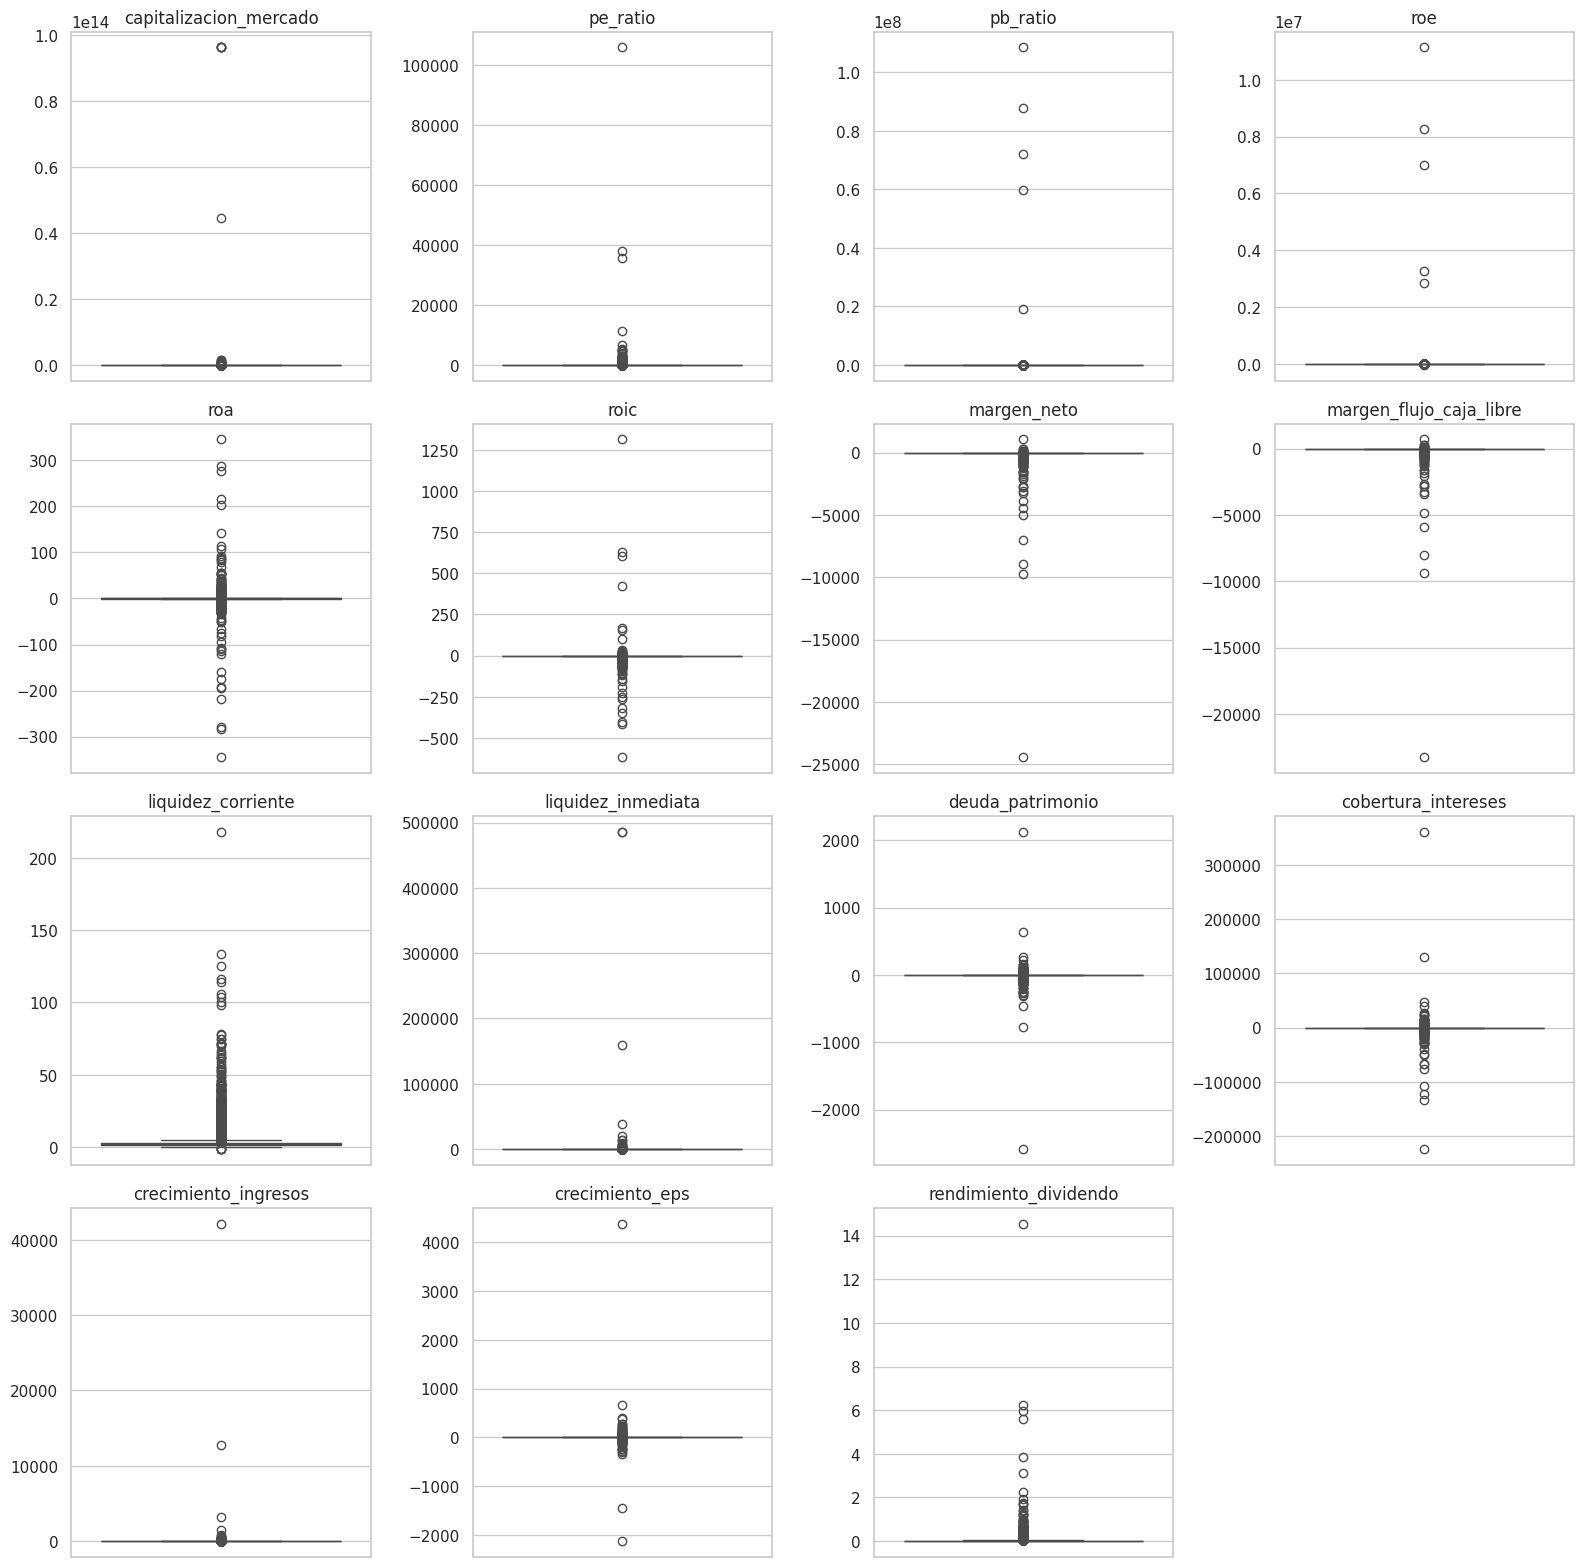

In [25]:
ncols = 4
nrows = -(-len(columnas_ratio) // ncols)  # redondeo hacia arriba
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))

for eje, columna in zip(axes.flat, columnas_ratio):
    sns.boxplot(y=df_reducido[columna], ax=eje, color="#4C72B0")
    eje.set_title(columna)
    eje.set_ylabel("")

for eje in axes.flat[len(columnas_ratio):]:
    eje.axis("off")

plt.tight_layout()
plt.show()

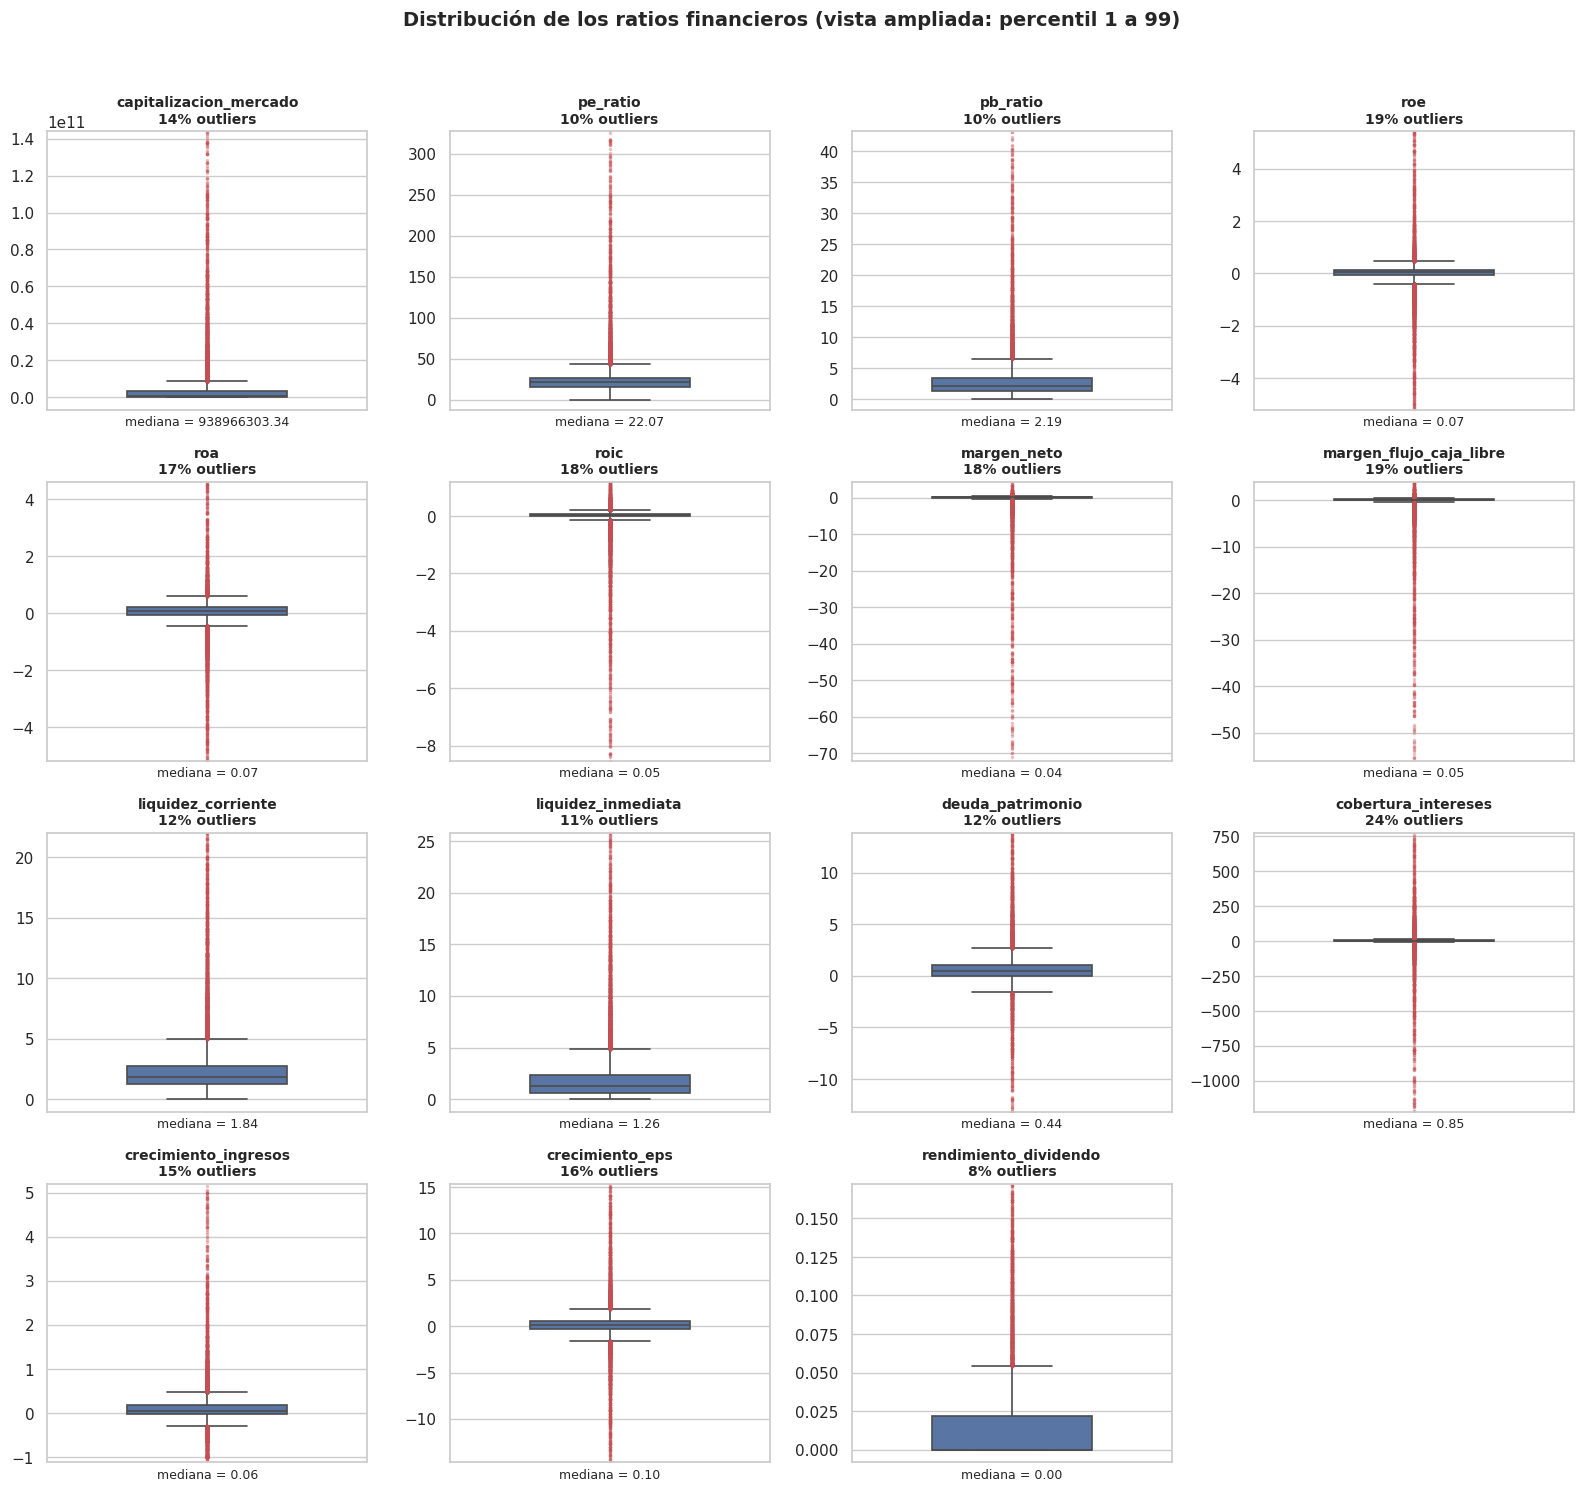

In [26]:
sns.set_theme(style="whitegrid")

ncols = 4
nrows = -(-len(columnas_ratio) // ncols)  # redondeo hacia arriba
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.8 * nrows))

for eje, columna in zip(axes.flat, columnas_ratio):
    datos = df_reducido[columna].dropna()

    sns.boxplot(
        y=datos, ax=eje, color="#4C72B0", width=0.5, linewidth=1.2,
        flierprops=dict(marker="o", markersize=2.5, alpha=0.35,
                        markerfacecolor="#C44E52", markeredgecolor="none"),
    )

    # Zoom: mostramos del percentil 1 al 99 para que la caja se vea
    p1, p99 = datos.quantile([0.01, 0.99])
    margen = (p99 - p1) * 0.05
    eje.set_ylim(p1 - margen, p99 + margen)

    # % de outliers según la regla del boxplot (1.5 * IQR)
    q1, q3 = datos.quantile([0.25, 0.75])
    iqr = q3 - q1
    pct_outliers = ((datos < q1 - 1.5 * iqr) | (datos > q3 + 1.5 * iqr)).mean() * 100

    eje.set_title(f"{columna}\n{pct_outliers:.0f}% outliers", fontsize=10, fontweight="bold")
    eje.set_ylabel("")
    eje.set_xticks([])
    eje.set_xlabel(f"mediana = {datos.median():.2f}", fontsize=9)

for eje in axes.flat[len(columnas_ratio):]:
    eje.axis("off")

fig.suptitle("Distribución de los ratios financieros (vista ampliada: percentil 1 a 99)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [27]:
def winsorizar(serie, percentil_bajo=0.01, percentil_alto=0.99):
    """Recorta una serie a sus percentiles bajo y alto."""
    limite_bajo = serie.quantile(percentil_bajo)
    limite_alto = serie.quantile(percentil_alto)
    return serie.clip(limite_bajo, limite_alto)

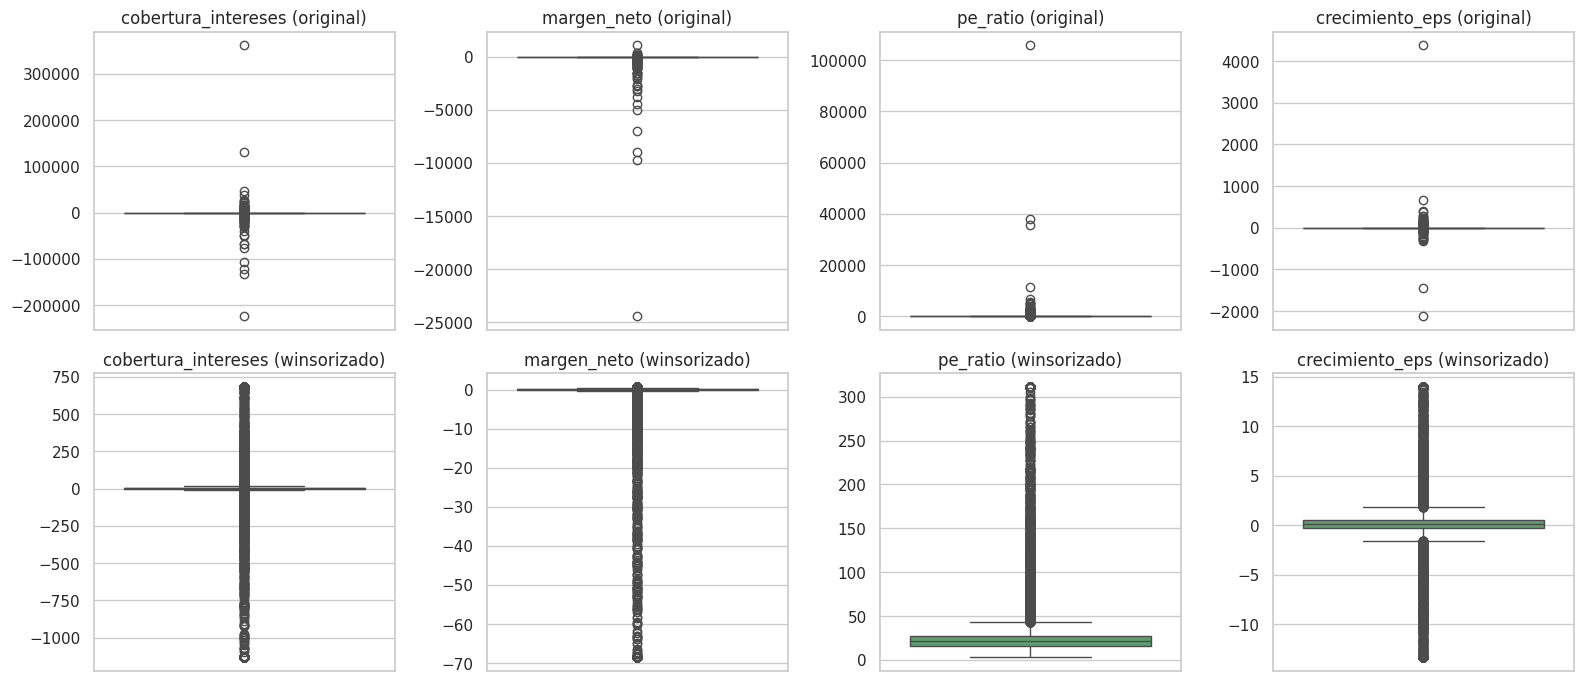

In [28]:
# Copia winsorizada (se conserva df_reducido para comparar)
df_winsor = df_reducido.copy()
for col in columnas_ratio:
    df_winsor[col] = winsorizar(df_winsor[col])

# Antes y después, en las variables con valores más extremos
variables = ["cobertura_intereses", "margen_neto", "pe_ratio", "crecimiento_eps"]
fig, ejes = plt.subplots(2, len(variables), figsize=(16, 7))
for j, v in enumerate(variables):
    sns.boxplot(y=df_reducido[v], ax=ejes[0, j], color="#4C72B0")
    ejes[0, j].set_title(f"{v} (original)")
    sns.boxplot(y=df_winsor[v], ax=ejes[1, j], color="#55A868")
    ejes[1, j].set_title(f"{v} (winsorizado)")
    for fila in (0, 1):
        ejes[fila, j].set_ylabel("")
plt.tight_layout()
plt.show()

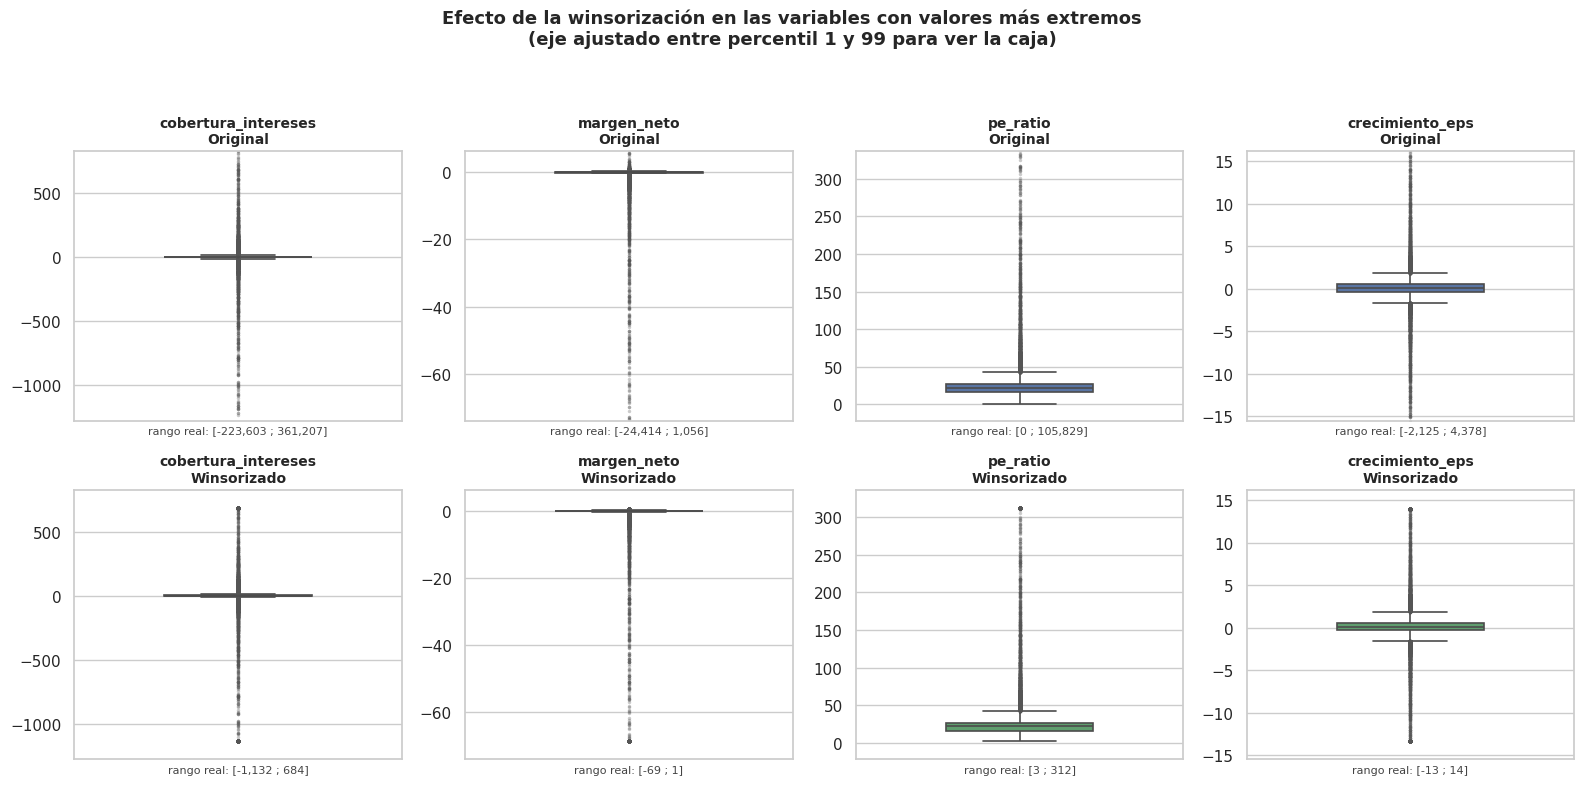

In [29]:
sns.set_theme(style="whitegrid")

# Copia winsorizada (se conserva df_reducido para comparar)
df_winsor = df_reducido.copy()
for col in columnas_ratio:
    df_winsor[col] = winsorizar(df_winsor[col])

variables = ["cobertura_intereses", "margen_neto", "pe_ratio", "crecimiento_eps"]

estilo_outliers = dict(marker="o", markersize=2.5, alpha=0.3,
                       markerfacecolor="#555555", markeredgecolor="none")

fig, ejes = plt.subplots(2, len(variables), figsize=(16, 8))

for j, v in enumerate(variables):
    for i, (datos, color, etiqueta) in enumerate([
        (df_reducido[v].dropna(), "#4C72B0", "Original"),
        (df_winsor[v].dropna(),   "#55A868", "Winsorizado"),
    ]):
        eje = ejes[i, j]
        sns.boxplot(y=datos, ax=eje, color=color, width=0.45,
                    linewidth=1.2, flierprops=estilo_outliers)

        # Zoom visual (no modifica los datos): percentil 1 a 99
        p1, p99 = datos.quantile([0.01, 0.99])
        margen = (p99 - p1) * 0.08
        eje.set_ylim(p1 - margen, p99 + margen)

        # Rango real, para no perder de vista lo que el zoom oculta
        eje.set_title(f"{v}\n{etiqueta}", fontsize=10, fontweight="bold")
        eje.set_xlabel(f"rango real: [{datos.min():,.0f} ; {datos.max():,.0f}]",
                       fontsize=8, color="#444444")
        eje.set_ylabel("")
        eje.set_xticks([])

fig.suptitle("Efecto de la winsorización en las variables con valores más extremos\n"
             "(eje ajustado entre percentil 1 y 99 para ver la caja)",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Dado la cantidad de datos financieros presentes y outliers muy amplios, buscamos opciones de visualización que permitieran apreciar mejor estos gráficos.

In [30]:
resumen_outliers = pd.DataFrame({
    "min_original": df_reducido[columnas_ratio].min(),
    "max_original": df_reducido[columnas_ratio].max(),
    "min_winsor": df_winsor[columnas_ratio].min(),
    "max_winsor": df_winsor[columnas_ratio].max(),
}).round(2)
resumen_outliers

,min_original,max_original,min_winsor,max_winsor
capitalizacion_mercado,0.00,9.619200e+13,6459741.72,1.370658e+11
pe_ratio,0.00,1.058287e+05,2.85,3.116600e+02
pb_ratio,0.00,1.084587e+08,0.32,4.117000e+01
roe,-34772.46,1.114114e+07,-4.73,4.940000e+00
roa,-344.44,3.456300e+02,-4.74,4.150000e+00
roic,-616.64,1.314330e+03,-8.09,7.400000e-01
margen_neto,-24414.00,1.056470e+03,-68.57,7.600000e-01
margen_flujo_caja_libre,-23256.00,6.898300e+02,-53.36,1.160000e+00
liquidez_corriente,-1.44,2.183000e+02,0.04,2.093000e+01
liquidez_inmediata,0.00,4.862113e+05,0.02,2.455000e+01


Los ratios tienen valores extremos muy lejos del resto: por ejemplo, `roe` va de -34.772 a +11.141.100 y `cobertura_intereses` de -223.603 a +361.207, cuando la gran mayoría de las empresas se mueve en rangos de pocas unidades. Con esos valores los boxplots quedan aplastados y los modelos lineales se distorsionan.

Se recorta cada ratio en los percentiles 1 y 99 (winsorización): se conservan todas las filas, pero los extremos pasan a valer el límite (por ejemplo, `roe` queda entre -4,73 y 4,94). No se recortan la variable objetivo ni `clase`. Para el modelo, estos límites se calcularán solo con los datos de entrenamiento.

In [31]:
df_winsor.to_csv("financial_data_limpio.csv", index=False)

## 6. Variable objetivo

,proporcion_sube,empresas
anio,,
2014,0.427,3626
2015,0.699,3825
2016,0.639,4061
2017,0.282,4125
2018,0.682,4140


Proporción general que sube: 0.546
clase coincide con (variación > 0) en el 99.9% de las filas


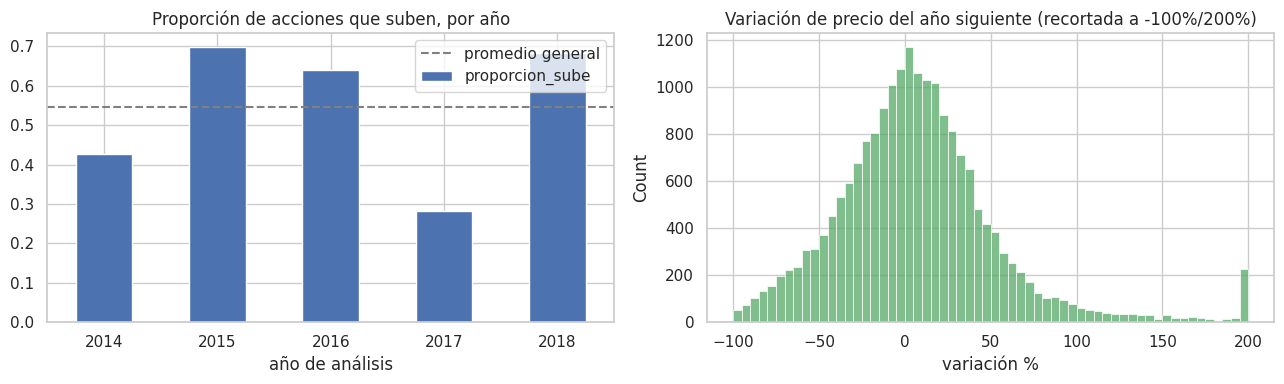

,variacion_precio_siguiente_anio
count,19777.0
mean,231.4
std,18152.5
min,-100.4
1%,-86.5
50%,3.9
99%,213.4
max,2418600.9


In [32]:
tabla_clase = df_reducido.groupby("anio")["clase"].agg(proporcion_sube="mean", empresas="size").round(3)
display(tabla_clase)
print("Proporción general que sube:", round(df_reducido["clase"].mean(), 3))
coincide = ((df_reducido["variacion_precio_siguiente_anio"] > 0).astype(int) == df_reducido["clase"]).mean()
print(f"clase coincide con (variación > 0) en el {coincide:.1%} de las filas")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
tabla_clase["proporcion_sube"].plot(kind="bar", ax=ejes[0], color="#4C72B0", rot=0)
ejes[0].axhline(df_reducido["clase"].mean(), color="gray", linestyle="--", label="promedio general")
ejes[0].set_title("Proporción de acciones que suben, por año")
ejes[0].set_xlabel("año de análisis")
ejes[0].legend()
sns.histplot(df_reducido["variacion_precio_siguiente_anio"].clip(-100, 200), bins=60, ax=ejes[1], color="#55A868")
ejes[1].set_title("Variación de precio del año siguiente (recortada a -100%/200%)")
ejes[1].set_xlabel("variación %")
plt.tight_layout()
plt.show()
display(df_reducido["variacion_precio_siguiente_anio"].describe(percentiles=[.01, .5, .99]).round(1))

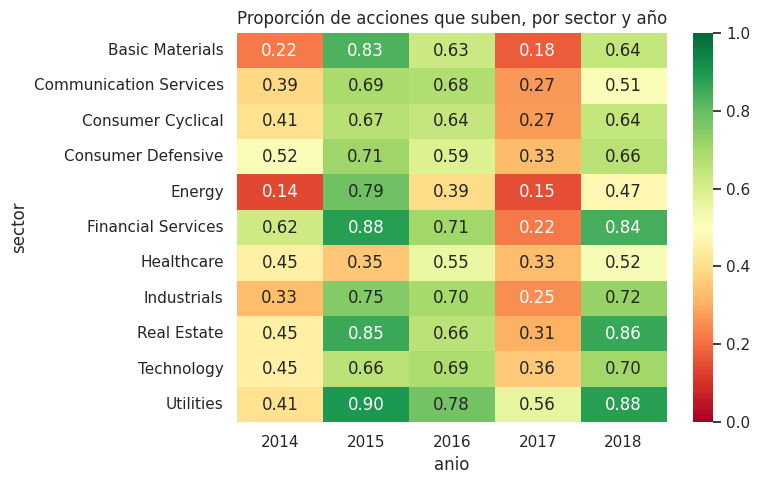

In [33]:
tabla_sector = df_reducido.pivot_table(index="sector", columns="anio", values="clase", aggfunc="mean")
plt.figure(figsize=(8, 5))
sns.heatmap(tabla_sector, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Proporción de acciones que suben, por sector y año")
plt.tight_layout()
plt.show()

- La proporción de acciones que suben cambia mucho según el año: 42,7% (2014), 69,9% (2015), 63,9% (2016), 28,2% (2017) y 68,2% (2018). Eso refleja el mercado en general más que a cada empresa.
- Los sectores siguen casi el mismo patrón: 2017 bajo y 2015 alto en la mayoría. Hay excepciones, como Healthcare en 2015 (35%) y Utilities en 2017 (56%).
- La variación de precio tiene valores extremos (máximo de +2.418.601%, con 38 filas por encima del +1.000%). `clase` coincide con "variación > 0" en el 99,9% de las filas y es una variable más robusta para clasificar.

## 7. Ratios y variable objetivo

Buscamos ver si los ratios financieros se comportan distinto entre las acciones que suben (clase 1) y las que no suben (clase 0).

/tmp/ipykernel_5908/1859120167.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_winsor, x="clase", y=v, ax=eje, showfliers=False, palette=["#C44E52", "#55A868"])
/tmp/ipykernel_5908/1859120167.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_winsor, x="clase", y=v, ax=eje, showfliers=False, palette=["#C44E52", "#55A868"])
/tmp/ipykernel_5908/1859120167.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_winsor, x="clase", y=v, ax=eje, showfliers=False, palette=["#C44E52", "#55A868"])
/tmp/ipykernel_5908/18591201

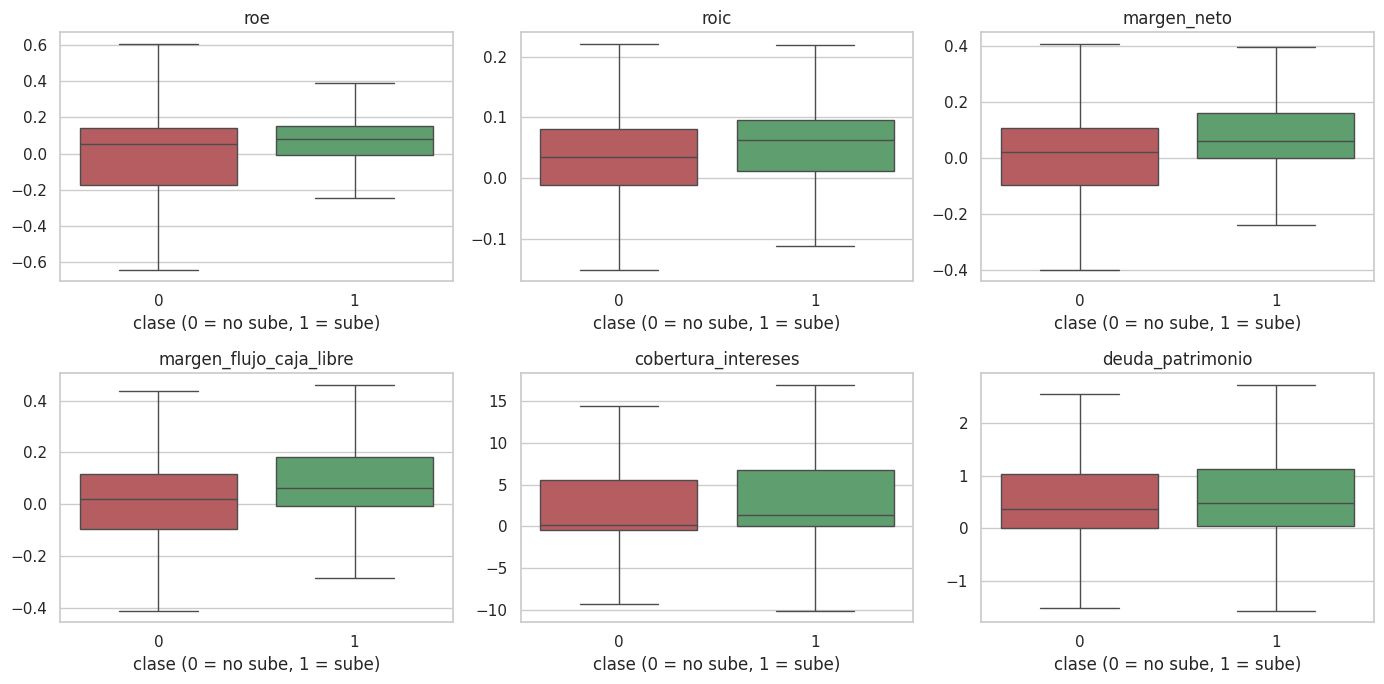

clase,0,1
capitalizacion_mercado,7.070394e+08,1.193441e+09
pe_ratio,2.306600e+01,2.122000e+01
pb_ratio,2.309000e+00,2.118000e+00
roe,5.200000e-02,8.200000e-02
roa,4.600000e-02,1.000000e-01
roic,3.500000e-02,6.200000e-02
margen_neto,2.200000e-02,6.100000e-02
margen_flujo_caja_libre,2.100000e-02,6.300000e-02
liquidez_corriente,1.837000e+00,1.866000e+00
liquidez_inmediata,1.355000e+00,1.192000e+00


In [34]:
variables = ["roe", "roic", "margen_neto", "margen_flujo_caja_libre", "cobertura_intereses", "deuda_patrimonio"]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, v in zip(ejes.flat, variables):
    sns.boxplot(data=df_winsor, x="clase", y=v, ax=eje, showfliers=False, palette=["#C44E52", "#55A868"])
    eje.set_title(v)
    eje.set_xlabel("clase (0 = no sube, 1 = sube)")
    eje.set_ylabel("")
plt.tight_layout()
plt.show()
display(df_winsor.groupby("clase")[columnas_ratio].median().T.round(3))

Buscaremos analizar si existe correlación entre las columnas predictoras a fin de descartar aquellas que puedan explicar de igual forma dada una alta correlación, como así también variables repetidas le dan más peso a una misma dimensión, y también para el modelo de clasificación.

Así también buscaremos visualizar que columnas pueden explicar más la variación de precio.

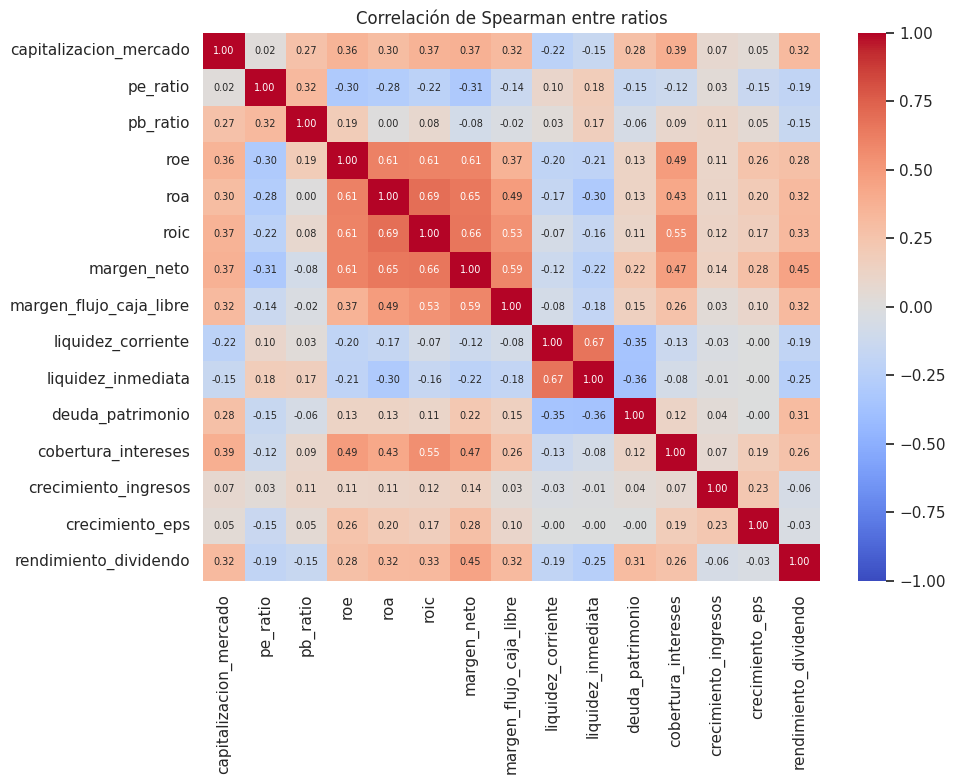

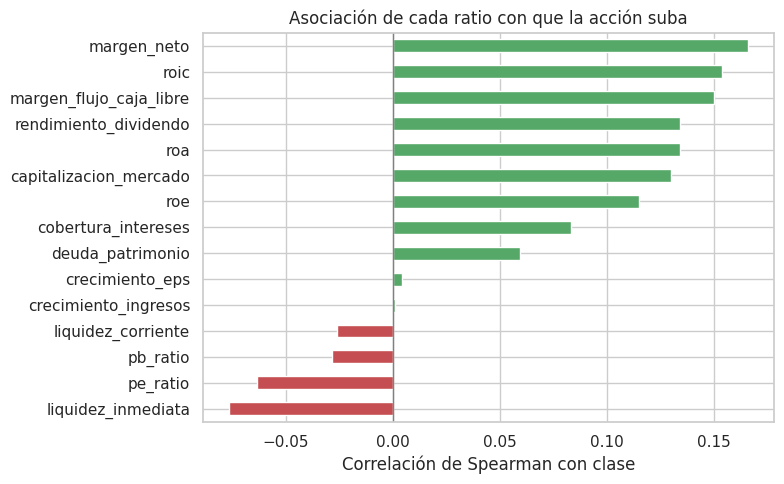

In [35]:
corr_ratios = df_winsor[columnas_ratio].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr_ratios, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlación de Spearman entre ratios")
plt.tight_layout()
plt.show()

corr_clase = df_winsor[columnas_ratio].corrwith(df_winsor["clase"], method="spearman").sort_values()
plt.figure(figsize=(8, 5))
corr_clase.plot(kind="barh", color=["#C44E52" if v < 0 else "#55A868" for v in corr_clase])
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Correlación de Spearman con clase")
plt.title("Asociación de cada ratio con que la acción suba")
plt.tight_layout()
plt.show()

Conclusiones
- Las empresas cuya acción sube tienen, en mediana, mayor rentabilidad: `roa` 0,100 contra 0,046, `roic` 0,062 contra 0,035, `margen_neto` 0,061 contra 0,022 y `margen_flujo_caja_libre` 0,063 contra 0,021. También tienen mayor cobertura de intereses (1,33 contra 0,12) y mayor capitalización.
- Las asociaciones individuales son débiles: la correlación de Spearman más alta es 0,17 (`margen_neto`), y `crecimiento_ingresos` y `crecimiento_eps` no se asocian prácticamente con la clase. Ningún ratio por sí solo separa bien las clases, así que se espera un poder predictivo modesto.
- Hay ratios muy relacionados entre sí: `roa`–`roic` (0,69), `liquidez_corriente`–`liquidez_inmediata` (0,67) y `roic`–`margen_neto` (0,66). Esto es multicolinealidad: afecta a los modelos lineales y los árboles lo toleran mejor.
- Entendemos que aquellos ratios muy relacionados entre si `roa`–`roic`–`margen_neto`–`margen_flujo_caja_libre` se debe a que utilizan los beneficios de la empresa como dato para su cálculo

## 8. Estructura temporal y por empresa

anio,2014,2015,2016,2017,2018
capitalizacion_mercado,9.492774e+08,8.046649e+08,9.852650e+08,1.071025e+09,9.328007e+08
pe_ratio,2.188000e+01,2.071400e+01,2.433300e+01,2.267900e+01,1.908200e+01
pb_ratio,2.336000e+00,2.064000e+00,2.351000e+00,2.386000e+00,1.942000e+00
roe,7.800000e-02,7.100000e-02,6.800000e-02,6.600000e-02,7.500000e-02
roa,8.200000e-02,7.400000e-02,6.500000e-02,6.700000e-02,7.300000e-02
roic,5.600000e-02,5.100000e-02,4.500000e-02,4.400000e-02,4.800000e-02
margen_neto,5.200000e-02,4.200000e-02,3.900000e-02,4.300000e-02,4.600000e-02
margen_flujo_caja_libre,3.400000e-02,4.600000e-02,5.200000e-02,4.700000e-02,4.500000e-02
liquidez_corriente,1.866000e+00,1.910000e+00,1.837000e+00,1.784000e+00,1.867000e+00
liquidez_inmediata,1.610000e+00,1.195000e+00,1.179000e+00,1.180000e+00,1.139000e+00


Empresas distintas: 4152


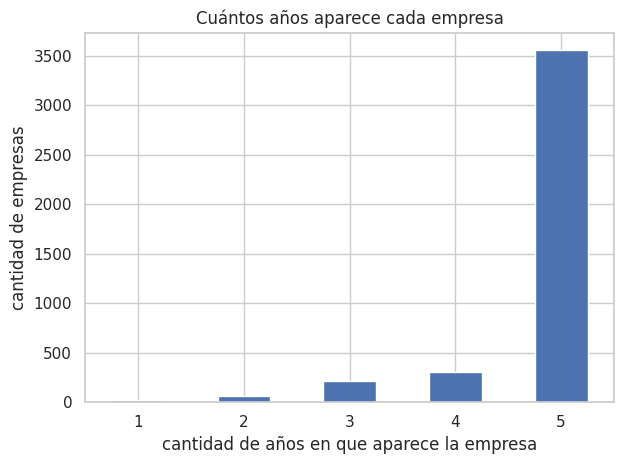

In [36]:
display(df_winsor.groupby("anio")[columnas_ratio].median().T.round(3))

anios_por_ticker = df_reducido.groupby("ticker")["anio"].nunique().value_counts().sort_index()
print("Empresas distintas:", df_reducido["ticker"].nunique())
anios_por_ticker.plot(kind="bar", color="#4C72B0", rot=0)
plt.xlabel("cantidad de años en que aparece la empresa")
plt.ylabel("cantidad de empresas")
plt.title("Cuántos años aparece cada empresa")
plt.tight_layout()
plt.show()

- Algunos ratios cambian de un año a otro: la mediana de `crecimiento_eps` es 0,195 en 2018 contra 0,045-0,104 entre 2014 y 2017, y la de `cobertura_intereses` baja de 1,35 (2014) a 0,40 (2016). Esto importa porque el modelo se entrena con unos años y se evalúa en otro.
- De las 4.152 empresas, 3.555 (85,6%) aparecen en los 5 años. Por eso la validación cruzada tiene que agrupar por empresa, para que una misma empresa no quede a la vez en entrenamiento y en prueba.

## 9. Conclusiones del EDA

1. **Datos:** 22.077 filas (empresa-año), de las que quedan 19.777 después de la limpieza. Son 4.152 empresas, 11 sectores y 15 ratios.
2. **Faltantes:** los ceros de `pe_ratio` y `pb_ratio` se trataron como faltantes (`pe_ratio` queda con 41,2% de datos vacíos), se eliminaron las filas con 9 o más ratios vacíos y el resto se imputó con la mediana de su sector y año.
3. **Outliers:** los ratios se recortaron en los percentiles 1 y 99.
4. **Variable objetivo:** la proporción de acciones que suben depende mucho del año (28% a 70%).
5. **Señal de los ratios:** las asociaciones con la clase son débiles (correlación de Spearman máxima de 0,17), con la rentabilidad como la familia más asociada. Se espera un poder predictivo modesto.


---
# Parte II. Modelo supervisado
## 10. ¿La acción sube el año siguiente?

**Problema:** clasificación binaria. A partir de los indicadores financiero-contables de una empresa en el año *t*, predecir si su acción **sube (1) o no (0)** durante el año *t+1* (`clase`). Usa los mismos 15 ratios + sector del EDA.

### Índice de la Parte II
* **10.0** Preparación del entorno.
* **10.1** Datos: se repiten las decisiones del EDA.
* **10.2** El problema y el piso de referencia.
* **10.3** La partición: por qué tiene que ser temporal.
* **10.4** Preprocesamiento dentro de un `Pipeline`.
* **10.5** Modelos base y validación cruzada.
* **10.6** Overfitting: la curva de validación del árbol.
* **10.7** Optimización de hiperparámetros.
* **10.8** Evaluación final en test (una sola vez).
* **10.9** Controles: ¿el modelo aprendió algo o está adivinando?
* **10.10** Interpretación.
* **10.11** Conclusiones.

### 10.0 Preparación del entorno

In [37]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score,
                             classification_report, f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
SEMILLA = 42

### 10.1 Datos: se repiten las decisiones del EDA

Partimos del archivo unificado que guardó el EDA (`financial_data_unificado.csv`) y repetimos, en una sola celda, las decisiones ya justificadas allí:

1. Nos quedamos con las 15 variables elegidas, más `Ticker`, `Year`, `Sector` y el objetivo, y las traducimos.
2. Los ceros de `pe_ratio` y `pb_ratio` se tratan como faltantes.
3. Se eliminan las filas con 9 o más de los 15 ratios vacíos.
4. No imputamos ni recortamos extremos acá, dado que lo realizaremos dentro del Pipeline más adelante.

In [38]:
def leer_csv(nombre):
    """Lee un CSV desde /content/ (Colab) y, si no existe, desde el directorio local."""
    try:
        return pd.read_csv("/content/" + nombre)
    except FileNotFoundError:
        return pd.read_csv(nombre)


traduccion = {
    "Ticker": "ticker", "Year": "anio", "Sector": "sector", "Market Cap": "capitalizacion_mercado",
    "PE ratio": "pe_ratio", "PB ratio": "pb_ratio", "ROE": "roe", "returnOnAssets": "roa", "ROIC": "roic",
    "Net Profit Margin": "margen_neto", "Free Cash Flow margin": "margen_flujo_caja_libre",
    "Current ratio": "liquidez_corriente", "quickRatio": "liquidez_inmediata",
    "Debt to Equity": "deuda_patrimonio", "Interest Coverage": "cobertura_intereses",
    "Revenue Growth": "crecimiento_ingresos", "EPS Growth": "crecimiento_eps",
    "Dividend Yield": "rendimiento_dividendo",
    "Price Var Next Year": "variacion_precio_siguiente_anio", "Class": "clase",
}
columnas_ratio = [
    "capitalizacion_mercado", "pe_ratio", "pb_ratio", "roe", "roa", "roic", "margen_neto",
    "margen_flujo_caja_libre", "liquidez_corriente", "liquidez_inmediata", "deuda_patrimonio",
    "cobertura_intereses", "crecimiento_ingresos", "crecimiento_eps", "rendimiento_dividendo",
]

df = leer_csv("financial_data_unificado.csv")
df = df[list(traduccion)].rename(columns=traduccion)

# Decisiones del EDA
df[["pe_ratio", "pb_ratio"]] = df[["pe_ratio", "pb_ratio"]].replace(0, np.nan)
faltantes_en_fila = df[columnas_ratio].isna().sum(axis=1)
df = df[faltantes_en_fila < 9].copy()

# Valores imposibles
df.loc[df["capitalizacion_mercado"] <= 0, "capitalizacion_mercado"] = np.nan
df.loc[df["liquidez_corriente"] < 0, "liquidez_corriente"] = np.nan

# La capitalización tiene valores desde millones hasta billones: usamos su logaritmo
df["log_capitalizacion"] = np.log10(df["capitalizacion_mercado"])

print("Filas:", len(df), "| Empresas:", df["ticker"].nunique())
df.head(3)

Filas: 19777 | Empresas: 4152


,ticker,anio,sector,capitalizacion_mercado,pe_ratio,pb_ratio,roe,roa,roic,margen_neto,margen_flujo_caja_libre,liquidez_corriente,liquidez_inmediata,deuda_patrimonio,cobertura_intereses,crecimiento_ingresos,crecimiento_eps,rendimiento_dividendo,variacion_precio_siguiente_anio,clase,log_capitalizacion
0,PG,2014,Consumer Defensive,2.126614e+11,18.7566,3.0391,0.1664,0.5765,0.0753,0.1565,0.1359,0.9370,0.506197,0.5061,21.4429,-0.0713,0.0371,0.0311,-9.323276,0,11.327689
1,VIPS,2014,Consumer Defensive,6.253200e+09,81.5526,NaN,0.3294,0.0403,0.0000,0.0364,0.0704,0.2102,0.849993,1.5093,15.4363,1.1737,1.4625,0.0000,-25.512193,0,9.796102
2,KR,2014,Consumer Defensive,1.827470e+10,12.0340,3.3579,0.2821,0.1011,0.0859,0.0154,0.0126,0.8250,0.141709,2.1007,6.1242,0.0182,0.0576,0.0174,33.118297,1,10.261850


### 10.2 El problema y el piso de referencia

Definimos `y = clase` (1 si la acción sube el año siguiente). Las variables predictoras son los 15 ratios (con la capitalización en logaritmo) y el sector. **Quedan afuera** `ticker` y `anio` (identificadores) y `variacion_precio_siguiente_anio`, que es la respuesta: dejarla en `X` sería hacer trampa.

Antes de modelar miramos cuánto vale el **piso**: lo que se logra sin aprender nada.

In [39]:
cols_num = ["log_capitalizacion", "pe_ratio", "pb_ratio", "roe", "roa", "roic", "margen_neto",
            "margen_flujo_caja_libre", "liquidez_corriente", "liquidez_inmediata", "deuda_patrimonio",
            "cobertura_intereses", "crecimiento_ingresos", "crecimiento_eps", "rendimiento_dividendo"]
cols_cat = ["sector"]

X = df[cols_num + cols_cat]
y = df["clase"]
grupos = df["ticker"]
anios = df["anio"]

print("Proporción general de acciones que suben:", round(y.mean(), 3))
df.groupby("anio")["clase"].agg(proporcion_sube="mean", empresas="size").round(3)

Proporción general de acciones que suben: 0.546


,proporcion_sube,empresas
anio,,
2014,0.427,3626
2015,0.699,3825
2016,0.639,4061
2017,0.282,4125
2018,0.682,4140


Evaluación del modelo y selección de métricas:
La proporción de acciones en alza varía sustancialmente según el año (entre un 28% y un 70%). En años con muchas incidencias a la alza, métricas tradicionales como la exactitud o el F1-score de la clase positiva pueden arrojar resultados engañosamente altos, premiando incluso a un modelo ingenuo que prediga siempre "sube". Es decir estaríamos considerando empresas que no subieron dentro de esta clase siendo esto erróneo.

Para evitar este sesgo por desbalance de clases, adoptamos el AUC (Área bajo la curva ROC) como métrica principal, complementada con la exactitud balanceada. Ambas métricas fijan un umbral neutro en 0,5 (azar), garantizando una medición objetiva del poder predictivo del modelo independientemente del contexto del mercado. Buscamos conocer efectivamente si el modelo detectó las que subieron ese año.

### 10.3 La partición: por qué tiene que ser temporal

Entrenamos con los años **2014 a 2017** y dejamos **2018** como test. Hay tres razones:

1. Se predice el futuro con datos del pasado, y no queremos que una partición al azar traiga datos de diversos años incluyendo 2018.
2. El mercado sube o baja casi todo junto en un año. Si mezclamos años, el modelo puede aprender "este año fue bueno" en lugar de "esta empresa es buena".
3. Una misma empresa aparece hasta 5 veces (una por año), con indicadores parecidos.

**Validación cruzada:** dentro del entrenamiento usamos folds **temporales**: entrenar con los años anteriores y validar en el siguiente (2015, 2016 y 2017).

In [40]:
es_train = (anios <= 2017).values
X_train, X_test = X[es_train], X[~es_train]
y_train, y_test = y[es_train], y[~es_train]
grupos_train = grupos[es_train]
anios_train = anios[es_train].values

print("Entrenamiento (2014-2017):", X_train.shape, "| proporción que sube:", round(y_train.mean(), 3))
print("Test (2018):              ", X_test.shape, "| proporción que sube:", round(y_test.mean(), 3))
print("Empresas del test que también están en el entrenamiento:",
      len(set(grupos[~es_train]) & set(grupos_train)), "de", grupos[~es_train].nunique())

# Folds temporales: entrenar con años anteriores, validar en el año siguiente
cv_temporal = [(np.where(anios_train < a)[0], np.where(anios_train == a)[0]) for a in (2015, 2016, 2017)]
# Folds agrupados por empresa (los de las notebooks de clase), solo para comparar
cv_empresas = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
                   .split(X_train, y_train, grupos_train))

Entrenamiento (2014-2017): (15637, 16) | proporción que sube: 0.51
Test (2018):               (4140, 16) | proporción que sube: 0.682
Empresas del test que también están en el entrenamiento: 4123 de 4140


### 10.4 Preprocesamiento dentro del `Pipeline`

Todo lo que "aprende" de los datos (la mediana para rellenar, los límites para recortar, la media para escalar) se calcula **solo con el entrenamiento** y se aplica después al test. Para eso va dentro del `Pipeline`.

* **Imputación** con la mediana, más una columna indicadora "el dato faltaba" por cada ratio con faltantes. Que falte el P/E puede ser informativo: probablemente la empresa no tiene ganancias positivas.
* **Recorte de extremos** (percentiles 1 y 99) y **escalado**: solo para la regresión logística, que es sensible a los valores extremos y a la escala. Los árboles no los necesitan.
* **Sector** con *one hot*.

El recorte no existe en scikit-learn, así que escribimos una pequeña clase `Winsorizador`. Aprende los límites en `fit` y recorta en `transform`.

In [41]:
class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta cada columna a sus percentiles bajo y alto (calculados con los datos de entrenamiento)."""

    def __init__(self, bajo=0.01, alto=0.99):
        self.bajo = bajo
        self.alto = alto

    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        self.lim_bajo_ = np.nanquantile(X, self.bajo, axis=0)
        self.lim_alto_ = np.nanquantile(X, self.alto, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_bajo_, self.lim_alto_)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_ if input_features is None else np.asarray(input_features, dtype=object)


def armar_preprocesador(lineal):
    pasos = [("recorte", Winsorizador())] if lineal else []
    pasos.append(("imputador", SimpleImputer(strategy="median", add_indicator=True)))
    if lineal:
        pasos.append(("escalador", StandardScaler()))
    return ColumnTransformer(
        [("num", Pipeline(pasos), cols_num),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_cat)],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def armar_modelo(clasificador, lineal=False):
    return Pipeline([("prep", armar_preprocesador(lineal)), ("clf", clasificador)])


# Comprobación: el preprocesador ajustado con el entrenamiento
prep_prueba = armar_preprocesador(lineal=False).fit(X_train)
print("Columnas que recibe el modelo:", prep_prueba.transform(X_train).shape[1])
print("Indicadores de dato faltante:", [c for c in prep_prueba.get_feature_names_out() if c.startswith("missingindicator")])

Columnas que recibe el modelo: 40
Indicadores de dato faltante: ['missingindicator_log_capitalizacion', 'missingindicator_pe_ratio', 'missingindicator_pb_ratio', 'missingindicator_roe', 'missingindicator_roa', 'missingindicator_roic', 'missingindicator_margen_neto', 'missingindicator_margen_flujo_caja_libre', 'missingindicator_liquidez_corriente', 'missingindicator_liquidez_inmediata', 'missingindicator_deuda_patrimonio', 'missingindicator_cobertura_intereses', 'missingindicator_crecimiento_ingresos', 'missingindicator_crecimiento_eps']


### 10.5 Modelos base y validación cruzada

Comparamos cuatro modelos vistos en clase: el **piso**, la regresión logística, un árbol de profundidad 4 y un Random Forest. Se comparan **solo con validación cruzada sobre el entrenamiento**: el test no se toca todavía.

Medimos AUC, exactitud balanceada y F1 con los folds temporales, y el AUC también con los folds agrupados por empresa para ver la diferencia.

In [ ]:
modelos = {
    "Piso (Dummy)": armar_modelo(DummyClassifier(strategy="prior")),
    "Regresión logística": armar_modelo(LogisticRegression(max_iter=1000), lineal=True),
    "Árbol (profundidad 4)": armar_modelo(DecisionTreeClassifier(max_depth=4, random_state=SEMILLA)),
    "Random Forest": armar_modelo(RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                                          random_state=SEMILLA, n_jobs=-1)),
}

def media_desvio(r, clave):
    return f"{r[clave].mean():.3f} ± {r[clave].std():.3f}"

filas = []
for nombre, modelo in modelos.items():
    r_t = cross_validate(modelo, X_train, y_train, cv=cv_temporal,
                         scoring=["roc_auc", "balanced_accuracy", "f1"])
    r_e = cross_validate(modelo, X_train, y_train, cv=cv_empresas, scoring=["roc_auc"])
    filas.append({"Modelo": nombre,
                  "AUC (cv temporal)": media_desvio(r_t, "test_roc_auc"),
                  "Exactitud balanceada (cv temporal)": media_desvio(r_t, "test_balanced_accuracy"),
                  "F1 (cv temporal)": media_desvio(r_t, "test_f1"),
                  "AUC (cv por empresa)": media_desvio(r_e, "test_roc_auc")})
pd.DataFrame(filas).set_index("Modelo")

- Los símbolos +- explican la variación entre cada pasada. Por ejemplo, la regresión logística tiene AUC = 0,545 ± 0,035. Eso quiere decir que, en promedio, dio 0,545, y que de un año a otro el AUC se movió típicamente unos 0,035 hacia arriba o abajo (más o menos entre 0,51 y 0,58).

- **La validación cruzada por empresa da un AUC más alto que la temporal**
- Todos los modelos superan al piso (AUC 0,5), pero por poco y con desvíos comparables a las diferencias entre modelos.
- El F1 del piso es engañoso (su valor depende de la proporción de clases del fold), así que no lo usamos para comparar.

### 10.6 Overfitting: la curva de validación del árbol

Como se vió en clase, vemos cómo cambia el AUC de un árbol al dejarlo crecer. Buscaremos la brecha entre el AUC de entrenamiento y el de validación temporal, que es el overfitting.

In [ ]:
profundidades = [1, 2, 3, 4, 6, 8, 12]
auc_tr, auc_va = [], []
for d in profundidades:
    arbol = armar_modelo(DecisionTreeClassifier(max_depth=d, random_state=SEMILLA))
    r = cross_validate(arbol, X_train, y_train, cv=cv_temporal, scoring="roc_auc", return_train_score=True)
    auc_tr.append(r["train_score"].mean())
    auc_va.append(r["test_score"].mean())

plt.plot(profundidades, auc_tr, "o-", label="Entrenamiento", color="#C44E52")
plt.plot(profundidades, auc_va, "o-", label="Validación cruzada temporal", color="#4C72B0")
plt.axhline(0.5, color="gray", linestyle="--", label="Azar")
plt.xlabel("Profundidad máxima del árbol")
plt.ylabel("AUC")
plt.title("Curva de validación del árbol de decisión")
plt.legend()
plt.tight_layout()
plt.show()

A medida que el árbol crece, el AUC de entrenamiento sube mucho (el árbol memoriza), pero el de validación **no mejora, y empeora**. La señal de los ratios es débil y ruidosa, así que los modelos simples funcionan mejor. Esto anticipa el resultado de la búsqueda de hiperparámetros.

### 10.7 Optimización de hiperparámetros

Elegimos los dos modelos más prometedores y buscamos sus hiperparámetros con `GridSearchCV`, con la **validación cruzada temporal** y el **AUC** como métrica, solo sobre el entrenamiento.

* **Random Forest:** cantidad de árboles, profundidad máxima y mínimo de muestras por hoja.
* **Regresión logística:** la fuerza de la regularización `C` (valores chicos regularizan más).

In [ ]:
grilla_rf = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [3, 5, 10, None],
    "clf__min_samples_leaf": [5, 20, 50],
}
busqueda_rf = GridSearchCV(
    armar_modelo(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)),
    param_grid=grilla_rf, cv=cv_temporal, scoring="roc_auc", n_jobs=1)
inicio = time.time()
busqueda_rf.fit(X_train, y_train)
print(f"Random Forest ({time.time() - inicio:.0f} segundos)")
print("  Mejores hiperparámetros:", busqueda_rf.best_params_)
print(f"  AUC en validación cruzada temporal: {busqueda_rf.best_score_:.3f}")

grilla_lr = {"clf__C": [0.001, 0.01, 0.1, 1, 10]}
busqueda_lr = GridSearchCV(
    armar_modelo(LogisticRegression(max_iter=1000), lineal=True),
    param_grid=grilla_lr, cv=cv_temporal, scoring="roc_auc")
busqueda_lr.fit(X_train, y_train)
print("Regresión logística")
print("  Mejores hiperparámetros:", busqueda_lr.best_params_)
print(f"  AUC en validación cruzada temporal: {busqueda_lr.best_score_:.3f}")

modelo_rf = busqueda_rf.best_estimator_
modelo_lr = busqueda_lr.best_estimator_

**Para discutir:** la búsqueda prefiere un Random Forest con árboles poco profundos (se queda con la profundidad más baja de la grilla) y una regresión logística muy regularizada. Los dos llegan a un AUC parecido y levemente mayor que sin ajustar. Es consistente con lo anterior: la señal es débil y gana la simplicidad. Como los dos empatan en validación, los llevamos a test como **finalistas**.

### 10.8 Evaluación final en test (una sola vez)

Usamos 2018 **una sola vez**, con los modelos ya elegidos y reentrenados con todo el entrenamiento (`best_estimator_`). Incluimos el piso como referencia.

In [ ]:
def metricas_test(modelo, nombre):
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"Modelo": nombre,
            "AUC": roc_auc_score(y_test, proba),
            "Exactitud balanceada": balanced_accuracy_score(y_test, pred),
            "Exactitud": (pred == y_test).mean(),
            "F1 (clase 'sube')": f1_score(y_test, pred),
            "% que predice 'sube'": pred.mean()}

piso = armar_modelo(DummyClassifier(strategy="prior")).fit(X_train, y_train)
tabla_test = pd.DataFrame([
    metricas_test(piso, "Piso (Dummy)"),
    metricas_test(modelo_lr, "Regresión logística (ajustada)"),
    metricas_test(modelo_rf, "Random Forest (ajustado)"),
]).set_index("Modelo").round(3)
print("Proporción real de acciones que suben en el test:", round(y_test.mean(), 3))
tabla_test

In [ ]:
proba_rf = modelo_rf.predict_proba(X_test)[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)
print(classification_report(y_test, pred_rf, target_names=["No sube", "Sube"]))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, display_labels=["No sube", "Sube"],
                                        cmap="Blues", ax=ejes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba_rf, ax=ejes[1], name="Random Forest")
RocCurveDisplay.from_predictions(y_test, modelo_lr.predict_proba(X_test)[:, 1], ax=ejes[1],
                                 name="Regresión logística")
ejes[1].plot([0, 1], [0, 1], "--", color="gray")
ejes[0].set_title("Matriz de confusión (Random Forest)")
ejes[1].set_title("Curva ROC")
plt.tight_layout()
plt.show()

* De la Matriz de Confusión vemos que el modelo tiene una buena predicción de valores positivos y negativos; además de efectuar falsos positivos muy bajos (que serían críticos en nuestro análisis dado que se informaría que una acción subió cuando en realidad cayó, pudiendo repercutir en la expectativa del mercado del usuario); frente a falsos negativos superiores a los anteriores (que resultarían de ser acciones que se predijeron a la baja pero subieron, resultando solamente un costo de oportunidad para el usuario).
* La exactitud casi no mejora con respecto del piso, y el F1 es mayor al de los modelos.


### 10.9 Controles: ¿el modelo aprendió algo o está adivinando?

Tres comprobaciones para no engañarnos.

**Control 1. Etiquetas mezcladas.** Se mezclan al azar las etiquetas del entrenamiento y se reentrena.

In [ ]:
rng = np.random.RandomState(SEMILLA)
aucs_mezcladas = []
for _ in range(5):
    y_mezclada = pd.Series(rng.permutation(y_train.values), index=y_train.index)
    modelo = clone(modelo_rf).fit(X_train, y_mezclada)
    aucs_mezcladas.append(roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1]))

print("AUC en test con etiquetas mezcladas (5 repeticiones):", np.round(aucs_mezcladas, 3))
print("AUC en test con etiquetas reales:", round(roc_auc_score(y_test, proba_rf), 3))

Con etiquetas mezcladas el AUC oscila entre 0,39 y 0,56: son valores de azar (con 4.140 filas del mismo año, el resultado se mueve bastante de una repetición a otra), todos muy por debajo del 0,73 con etiquetas reales. El proceso no filtra información del test.

**Control 2. ¿Es estable el resultado entre años?** Un solo año de test puede ser favorable o desfavorable por casualidad. Para ver cuánto varía, calculamos el AUC **dentro de cada año**, entrenando con los otros cuatro.

In [ ]:
resultados_anio = {}
for nombre, modelo in [("Regresión logística", modelo_lr), ("Random Forest", modelo_rf)]:
    aucs = []
    for a in range(2014, 2019):
        m = clone(modelo).fit(X[anios != a], y[anios != a])
        aucs.append(roc_auc_score(y[anios == a], m.predict_proba(X[anios == a])[:, 1]))
    resultados_anio[nombre] = aucs

auc_por_anio = pd.DataFrame(resultados_anio, index=range(2014, 2019))
ax = auc_por_anio.plot(kind="bar", rot=0, color=["#55A868", "#4C72B0"])
ax.axhline(0.5, color="gray", linestyle="--")
ax.set_ylabel("AUC dentro del año")
ax.set_xlabel("año de análisis")
ax.set_title("AUC por año (entrenando con los otros cuatro años)")
plt.tight_layout()
plt.show()
auc_por_anio.round(3)

El AUC cambia bastante de un año a otro: 2018 es el año donde los ratios separan mejor, y 2017 el peor. Hay que tener cuidado: **el resultado en el test de 2018 es el más favorable de los cinco años**, y creemos que no debe tomarse en cuenta dado que se lo ve muy favorable.

**Control 3. Un objetivo que no depende del mercado.** Cambiamos la variable a predecir: en lugar de "sube", buscamos **"sube más que la mediana de su año"**. Así se elimina el efecto del mercado y las clases quedan 50/50.

In [ ]:
mediana_anio = df.groupby("anio")["variacion_precio_siguiente_anio"].transform("median")
y_rel = (df["variacion_precio_siguiente_anio"] > mediana_anio).astype(int)
y_rel_train, y_rel_test = y_rel[es_train], y_rel[~es_train]

filas = []
for nombre, modelo in [("Regresión logística", modelo_lr), ("Random Forest", modelo_rf)]:
    r = cross_validate(clone(modelo), X_train, y_rel_train, cv=cv_temporal, scoring="roc_auc")
    m = clone(modelo).fit(X_train, y_rel_train)
    filas.append({"Modelo": nombre,
                  "AUC cv temporal": r["test_score"].mean(),
                  "AUC test 2018": roc_auc_score(y_rel_test, m.predict_proba(X_test)[:, 1])})
print("Proporción que 'sube más que la mediana' en el test:", round(y_rel_test.mean(), 3))
pd.DataFrame(filas).set_index("Modelo").round(3)

Con este objetivo el AUC baja y queda más cerca del de la validación cruzada temporal. Dado que el año 2018 fue muy favorable, queda desvalanceado a la hora de generar predicciones positivas de negativas.

### 10.11 Conclusiones

1. **Se puede predecir algo, pero poco.** Con la validación temporal, el AUC ronda 0,58-0,59 con los modelos ajustados (azar = 0,5). En el test de 2018 llega a 0,73 con los dos finalistas (regresión logística y Random Forest).
2. **El resultado de 2018 es optimista.** Dentro de cada año el AUC va de 0,51 (2017) a 0,73 (2018), y con el objetivo "sube más que la mediana del año" el AUC en test baja a 0,63-0,64. Una parte de lo que predice el modelo es "cómo le fue al mercado".
3. **Exactitud y F1 no sirven para comparar acá**: el piso "siempre sube" acierta 68% en 2018. Usamos AUC y exactitud balanceada.
